# Baseline comparison — Kamiran & Calders

Comparison charts of the 4 baselines, absolute rates per sensitive group and TPR/FPR pivots, for **logistic regression** and **XGBoost**.

Filters applied to every result (`src/results/all/`):
- `fairness_correction == 'kamiran_rw'` — APR runs (`adaptative_rw`) are excluded;
- `train_window == 'none'` — unbounded history for `dynamic`/`abcinml` (`vanilla`/`static` do not depend on `train_window`);
- `forecasting_technique == 'sma'` — as in `04_results_overview.ipynb`.

Figures are saved to `src/notebooks/figures/baselines_comparison/`. The chart code replicates the one in `04_results_overview.ipynb`.

In [1]:
import sys
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt

# The notebook lives in src/notebooks/ -> repo root is two levels up
ROOT = Path.cwd().resolve()
while not (ROOT / 'src' / 'utils' / 'metrics_utils.py').exists():
    ROOT = ROOT.parent
sys.path.append(str(ROOT / 'src' / 'utils'))

from metrics_utils import (
    _SNAPSHOT_METRICS,
    _BASELINE_ORDER,
    _BASELINE_COLORS,
    _BATCH_FORMAT,
    _batch_to_datetime,
    _build_ma_series,
    _add_period_spans,
    _apply_bin_xticks,
)

MODELS = ['logistic_regression', 'xgboost']
MODEL_ABBR = {'logistic_regression': 'lr', 'xgboost': 'xgboost'}


fig_dir = ROOT / 'src' / 'notebooks' / 'figures' / 'baselines_comparison'
fig_dir.mkdir(parents=True, exist_ok=True)

## Loading and filters

In [2]:
def load_filtered(csv_name, models=MODELS):
    """Read an aggregated CSV and apply the notebook filters (kamiran_rw, train_window none, sma)."""
    df = pd.read_csv(ROOT / 'src' / 'results' / 'all' / csv_name, low_memory=False)
    df = df[
        (df['fairness_correction'] == 'kamiran_rw')
        & (df['train_window'].astype(str) == 'none')
        & (df['forecasting_technique'] == 'sma')
        & (df['model_name'].isin(models))
    ].copy()
    return df


assessment_df = load_filtered('assessment_all_baselines.csv')
absolute_df = load_filtered('absolute_results_df.csv')

metric_cols = [col for col, _ in _SNAPSHOT_METRICS]
rate_cols = ['tpr_S0', 'fpr_S0', 'tpr_S1', 'fpr_S1']

print('fairness_correction:', assessment_df['fairness_correction'].unique().tolist())
print('train_window:', assessment_df['train_window'].astype(str).unique().tolist())
assessment_df.groupby(['model_name', 'batch_type', 'baseline']).size().unstack('baseline')

fairness_correction: ['kamiran_rw']
train_window: ['none']


baseline                        abcinml  dynamic  static  vanilla
model_name          batch_type                                   
logistic_regression monthly        2640      240     240      240
                    weekly        11649     1059    1059     1059
xgboost             monthly        2640      240     240      240
                    weekly        11649     1059    1059     1059

## Comparison of the 4 baselines — monthly and weekly

One figure per model: two rows of subplots (one per `batch_type`), moving average of the metrics per batch (mean over alphas and forecast windows for `abcinml`).

In [3]:
def plot_baselines_row(axes, assessment_df, batch_type, moving_avg_window):
    """Replicate the logic of _generate_comparative_chart on one row of axes."""
    df = assessment_df.copy()
    df['batch_dt'] = _batch_to_datetime(df['batch'].astype(str).tolist(), batch_type)
    df = df.groupby(['baseline', 'batch', 'batch_dt'], as_index=False)[metric_cols].mean()

    present_baselines = [b for b in _BASELINE_ORDER if b in df['baseline'].unique()]

    common_dates = None
    for bt in present_baselines:
        dates = set(df[df['baseline'] == bt]['batch_dt'])
        common_dates = dates if common_dates is None else common_dates & dates
    common_dates = sorted(common_dates) if common_dates else []

    metric_ylims = {}
    for col, _ in _SNAPSHOT_METRICS:
        values = assessment_df[col].dropna()
        if len(values) == 0:
            continue
        vmin, vmax = values.min(), values.max()
        padding = (vmax - vmin) * 0.05
        metric_ylims[col] = (vmin - padding, vmax + padding)

    all_batch_labels = sorted(df['batch'].astype(str).unique())

    baseline_handles, period_handles = [], []
    for col_idx, (col, label) in enumerate(_SNAPSHOT_METRICS):
        ax = axes[col_idx]

        handles = _add_period_spans(ax, all_batch_labels, batch_type)
        if not period_handles:
            period_handles = handles

        if col in ('dp', 'tpr_diff', 'fpr_diff'):
            ax.axhline(y=0, color='black', linestyle='--', linewidth=1.0, alpha=0.5, zorder=2)

        for bt in present_baselines:
            sub = df[df['baseline'] == bt]
            ma = _build_ma_series(sub, col, moving_avg_window)
            ma = ma[ma.index.isin(common_dates)] if common_dates else ma

            fmt = _BATCH_FORMAT[batch_type]
            x_pos = [all_batch_labels.index(d.strftime(fmt)) for d in ma.index if d.strftime(fmt) in all_batch_labels]
            line, = ax.plot(
                x_pos, ma.values,
                color=_BASELINE_COLORS.get(bt, None),
                linewidth=2.5,
                label=bt,
                zorder=3,
            )
            if col_idx == 0:
                baseline_handles.append(line)

        ax.set_title(label, fontsize=15, fontweight='bold')
        ax.set_ylabel(label, fontsize=15)
        if col in metric_ylims:
            ax.set_ylim(metric_ylims[col])
        _apply_bin_xticks(ax, all_batch_labels)
        ax.tick_params(axis='x', labelsize=13)
        ax.tick_params(axis='y', labelsize=13)

    return baseline_handles, period_handles


def plot_baselines_comparison(model_name):
    model_df = assessment_df[assessment_df['model_name'] == model_name]
    fig = plt.figure(figsize=(28, 13), layout='constrained')
    subfigs = fig.subfigures(2, 1)

    rows = [
        ('monthly', model_df[model_df['batch_type'] == 'monthly'], 5),
        ('weekly', model_df[model_df['batch_type'] == 'weekly'], 20),
    ]

    baseline_handles, period_handles = [], []
    for subfig, (batch_type, df_row, ma_window) in zip(subfigs, rows):
        axes = subfig.subplots(1, len(_SNAPSHOT_METRICS))
        subfig.suptitle(f'batch type = {batch_type}', fontsize=15, fontweight='bold')
        bh, ph = plot_baselines_row(axes, df_row, batch_type, ma_window)
        if not baseline_handles:
            baseline_handles, period_handles = bh, ph

    # Post-plot tweaks: span alpha (same as EDA fig1) and font of the vline labels
    for ax in fig.axes:
        for patch in ax.patches:
            patch.set_alpha(0.20)
        for text in ax.texts:
            text.set_fontsize(13)

    all_handles = baseline_handles + period_handles
    legend_labels = [h.get_label() for h in all_handles]
    leg = fig.legend(
        all_handles, legend_labels,
        loc='outside lower center', ncol=len(all_handles), fontsize=20, framealpha=0.9,
    )
    for legend_patch in leg.get_patches():
        legend_patch.set_alpha(0.4)

    fig_path = fig_dir / f'baselines_comparison_{MODEL_ABBR[model_name]}.png'
    fig.savefig(fig_path, dpi=120, bbox_inches='tight')
    plt.show()

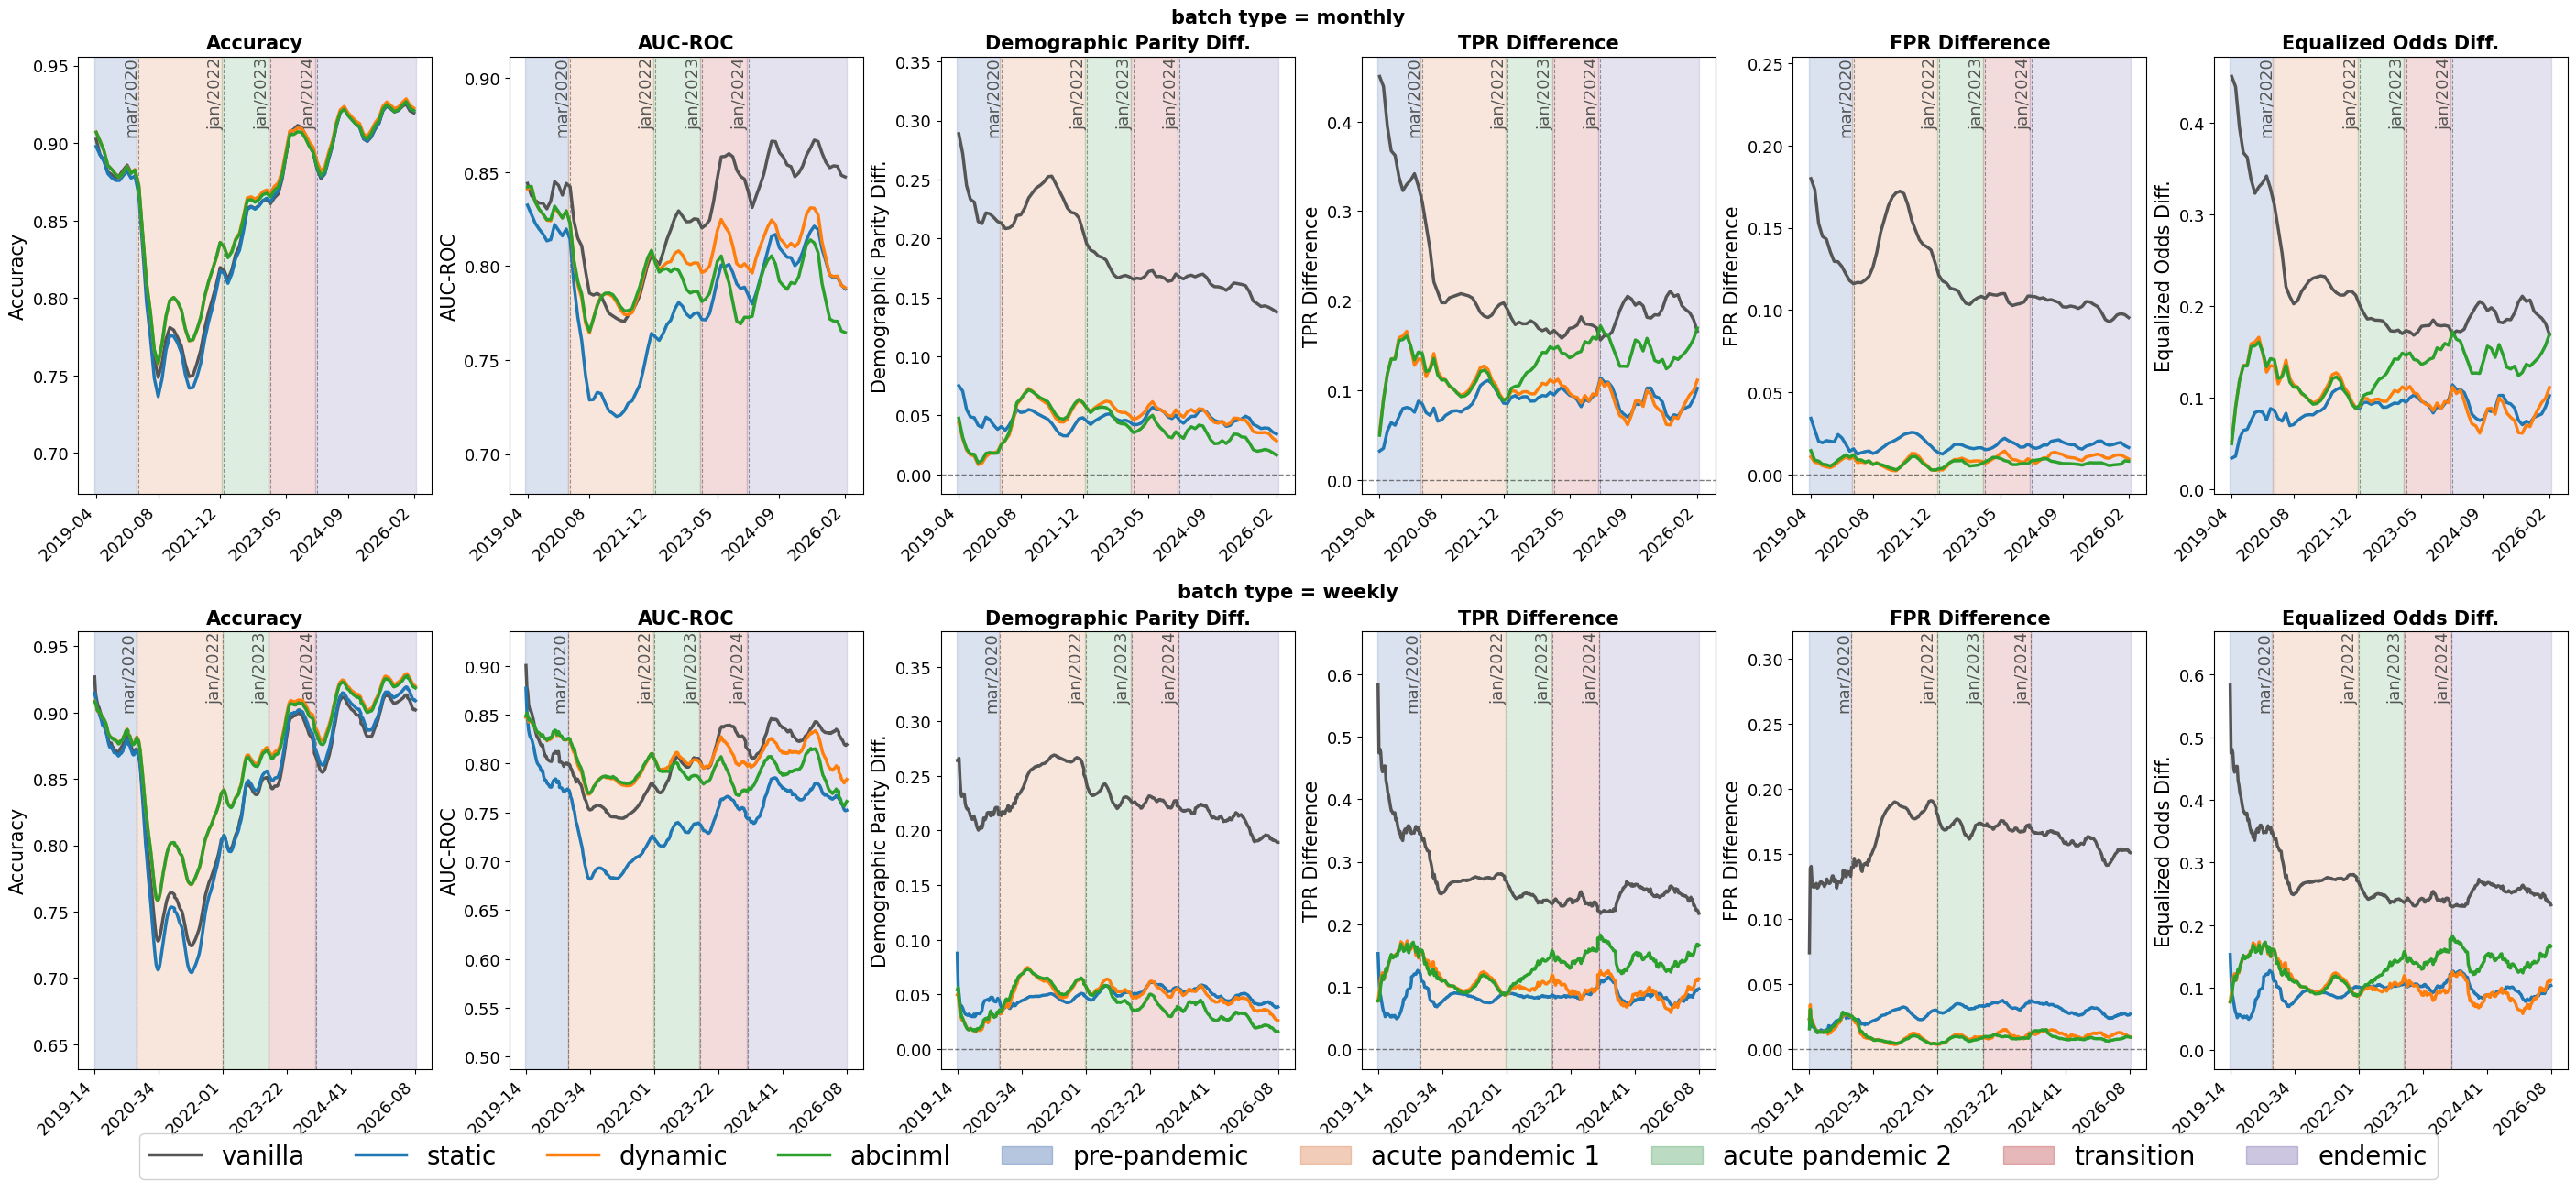

In [4]:
plot_baselines_comparison('logistic_regression')

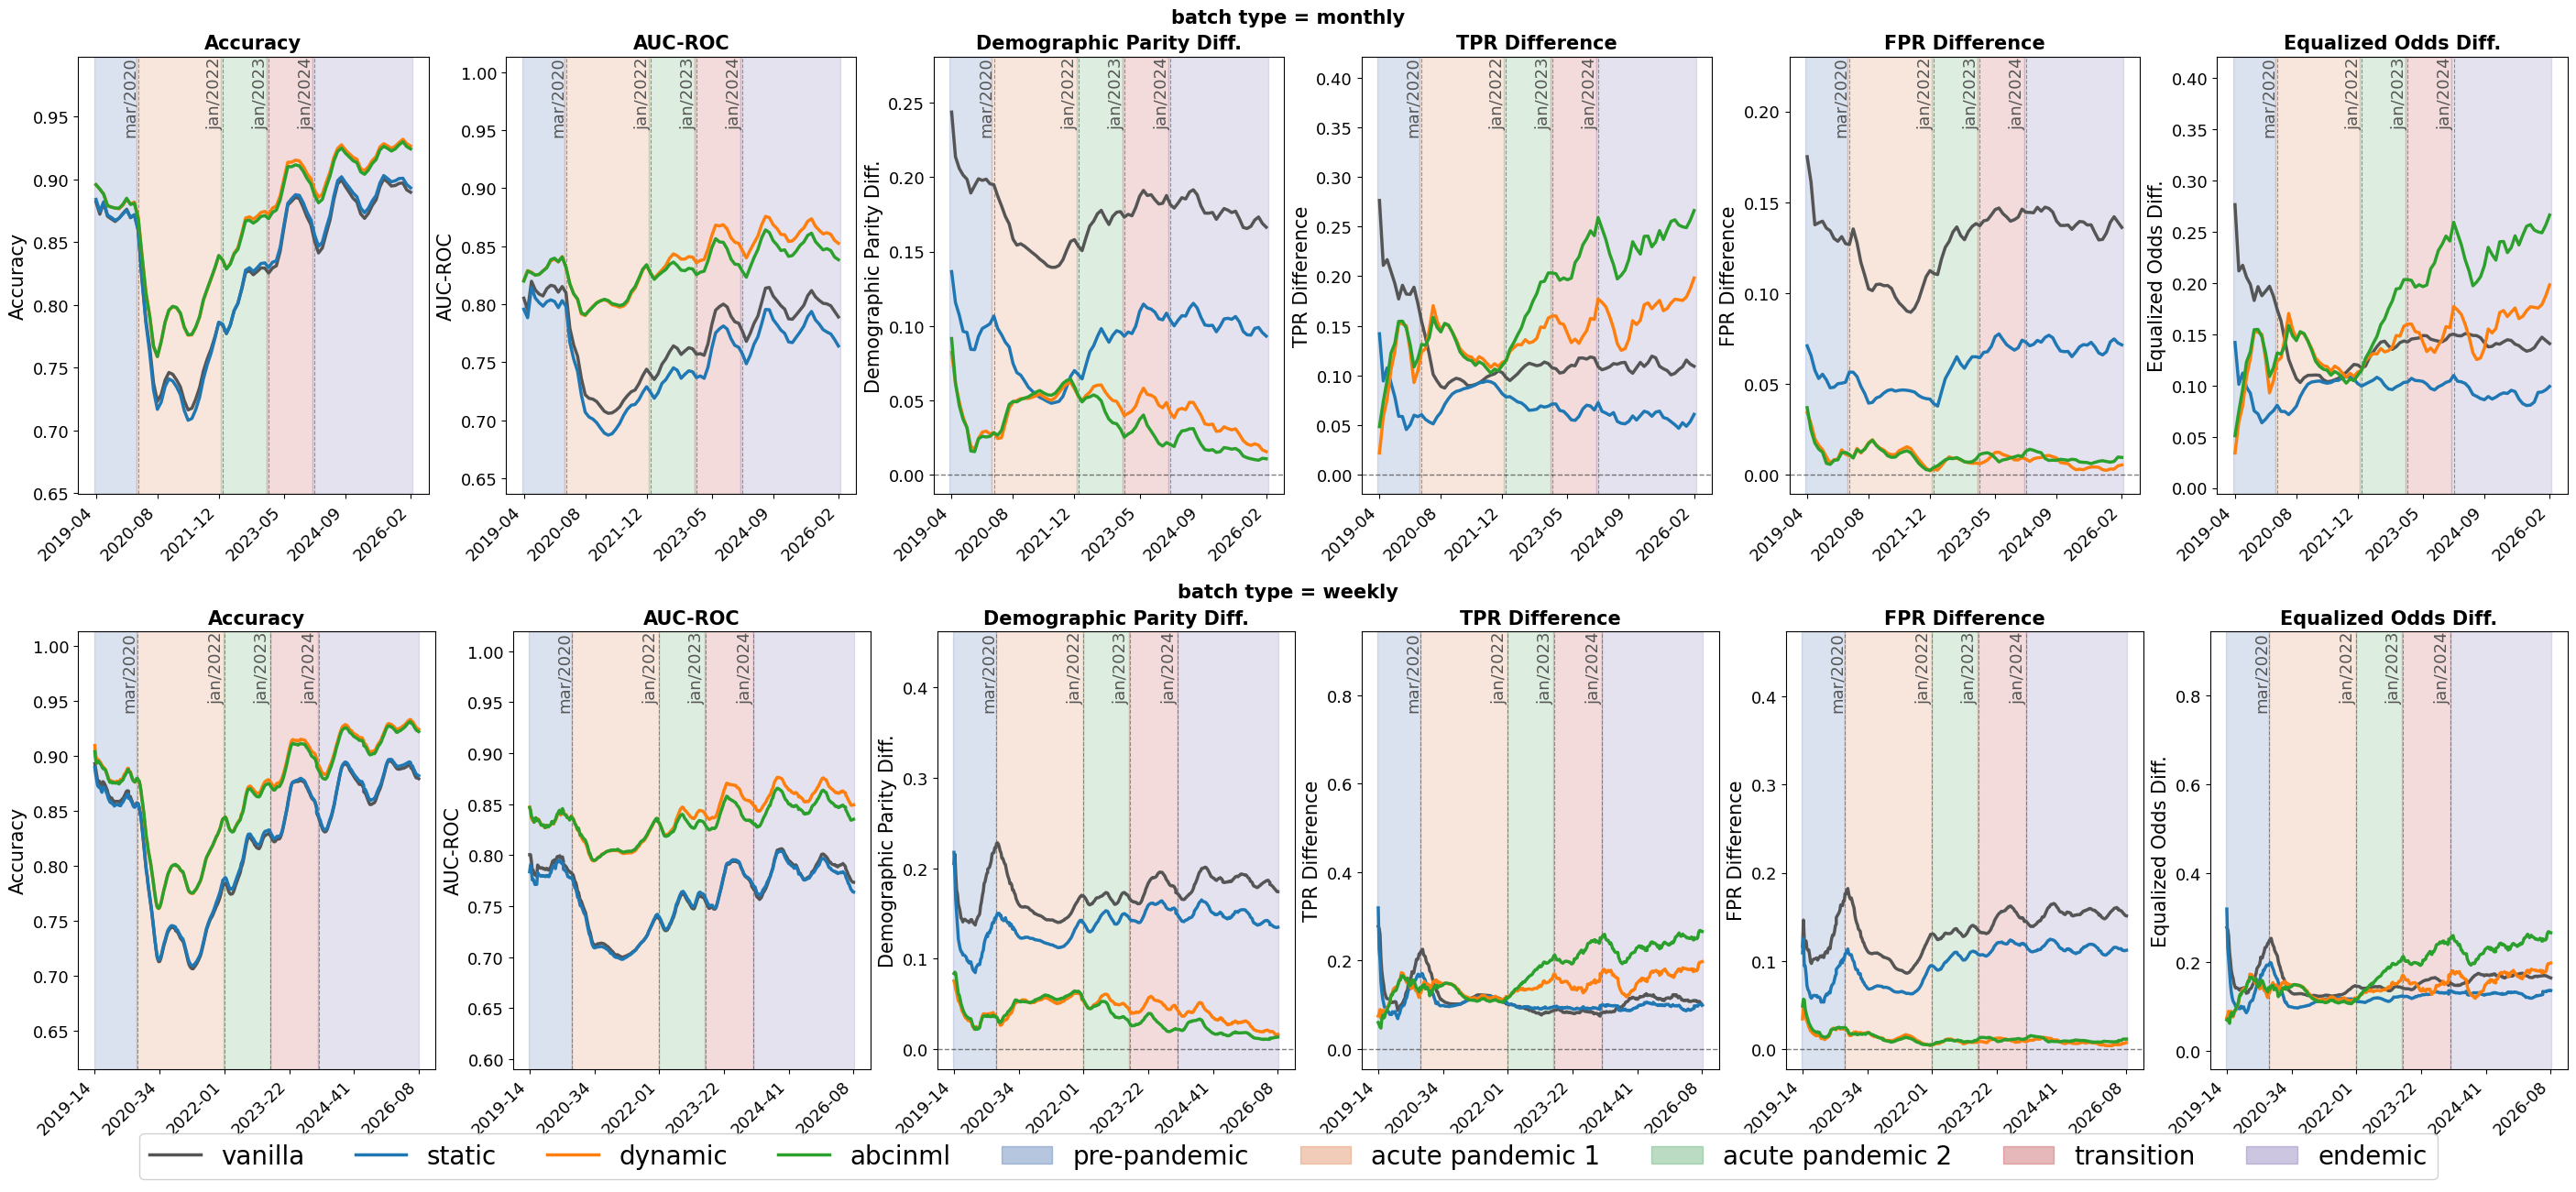

In [5]:
plot_baselines_comparison('xgboost')

## Absolute rates per sensitive group — mean per baseline (monthly)

TPR and FPR of each group (S0 privileged, S1 sensitive) over time, one row per baseline. 10-batch moving average, as in the pipeline.

In [6]:
_MA_WINDOW = 10  # pipeline default for monthly
_S0_COLOR = '#ff7f0e'
_S1_COLOR = '#1f77b4'


def plot_absolute_rates(model_name, batch_type='monthly'):
    abs_m = absolute_df[
        (absolute_df['model_name'] == model_name)
        & (absolute_df['batch_type'] == batch_type)
    ].copy()
    abs_m['batch_dt'] = _batch_to_datetime(abs_m['batch'].astype(str).tolist(), batch_type)

    # Mean per (baseline, batch): collapses alphas and forecast windows
    abs_mean = abs_m.groupby(['baseline', 'batch', 'batch_dt'], as_index=False)[rate_cols].mean()

    present_baselines = [b for b in _BASELINE_ORDER if b in abs_mean['baseline'].unique()]
    n_rows = len(present_baselines)
    all_batch_labels = sorted(abs_mean['batch'].astype(str).unique())

    tpr_values = pd.concat([abs_mean['tpr_S0'], abs_mean['tpr_S1']])
    tpr_pad = (tpr_values.max() - tpr_values.min()) * 0.05
    tpr_ylim = (tpr_values.min() - tpr_pad, tpr_values.max() + tpr_pad)

    fpr_values = pd.concat([abs_mean['fpr_S0'], abs_mean['fpr_S1']])
    fpr_pad = (fpr_values.max() - fpr_values.min()) * 0.05
    fpr_ylim = (fpr_values.min() - fpr_pad, fpr_values.max() + fpr_pad)

    rate_pairs = [
        ('tpr_S0', 'tpr_S1', 'TPR (True Positive Rate)', tpr_ylim),
        ('fpr_S0', 'fpr_S1', 'FPR (False Positive Rate)', fpr_ylim),
    ]

    fig, axes = plt.subplots(n_rows, 2, figsize=(20, 5 * n_rows), squeeze=False, layout='constrained')

    period_handles = []
    for row, bt in enumerate(present_baselines):
        sub = abs_mean[abs_mean['baseline'] == bt].sort_values('batch_dt').reset_index(drop=True)
        x_str = sub['batch'].astype(str).tolist()
        x_idx = [all_batch_labels.index(b) for b in x_str if b in all_batch_labels]

        for col_idx, (col_s0, col_s1, col_label, ylim) in enumerate(rate_pairs):
            ax = axes[row][col_idx]

            handles = _add_period_spans(ax, all_batch_labels, batch_type)
            if not period_handles:
                period_handles = handles

            ma_s0 = sub[col_s0].rolling(window=_MA_WINDOW, min_periods=1).mean().values
            ma_s1 = sub[col_s1].rolling(window=_MA_WINDOW, min_periods=1).mean().values

            line_s0, = ax.plot(x_idx, ma_s0, color=_S0_COLOR, linewidth=2.0, label='S0 (privileged)')
            line_s1, = ax.plot(x_idx, ma_s1, color=_S1_COLOR, linewidth=2.0, label='S1 (sensitive)')
            ax.fill_between(x_idx, ma_s0, ma_s1, alpha=0.15, color='gray')

            ax.set_title(col_label, fontsize=15, fontweight='bold')
            ax.set_ylabel(col_label, fontsize=15)
            ax.set_ylim(ylim)
            # Inner legend with the group lines only (periods go in the main legend)
            ax.legend(handles=[line_s0, line_s1], fontsize=13, framealpha=0.9)
            _apply_bin_xticks(ax, all_batch_labels)
            ax.tick_params(axis='x', labelsize=13)
            ax.tick_params(axis='y', labelsize=13)

        # Baseline label above the row (right column, as in the pipeline)
        axes[row][1].annotate(
            f'Baseline: {bt}',
            xy=(0.5, 1.08),
            xycoords='axes fraction',
            ha='center',
            va='bottom',
            fontsize=15,
            fontweight='bold',
            bbox=dict(boxstyle='round,pad=0.4', facecolor='#f0f0f0', edgecolor='#888888', alpha=0.9),
        )

    # Post-plot tweaks: span alpha and font of the vline labels —
    # only the date texts (they contain '/'), keeping the annotations
    for ax in fig.axes:
        for patch in ax.patches:
            patch.set_alpha(0.20)
        for text in ax.texts:
            if '/' in text.get_text():
                text.set_fontsize(13)

    period_labels = [h.get_label() for h in period_handles]
    leg = fig.legend(
        period_handles, period_labels,
        loc='outside lower center', ncol=len(period_handles), fontsize=20, framealpha=0.9,
    )
    for legend_patch in leg.get_patches():
        legend_patch.set_alpha(0.4)

    out_path = fig_dir / f'absolute_rates_by_group_{MODEL_ABBR[model_name]}.png'
    fig.savefig(out_path, dpi=120, bbox_inches='tight')
    plt.show()

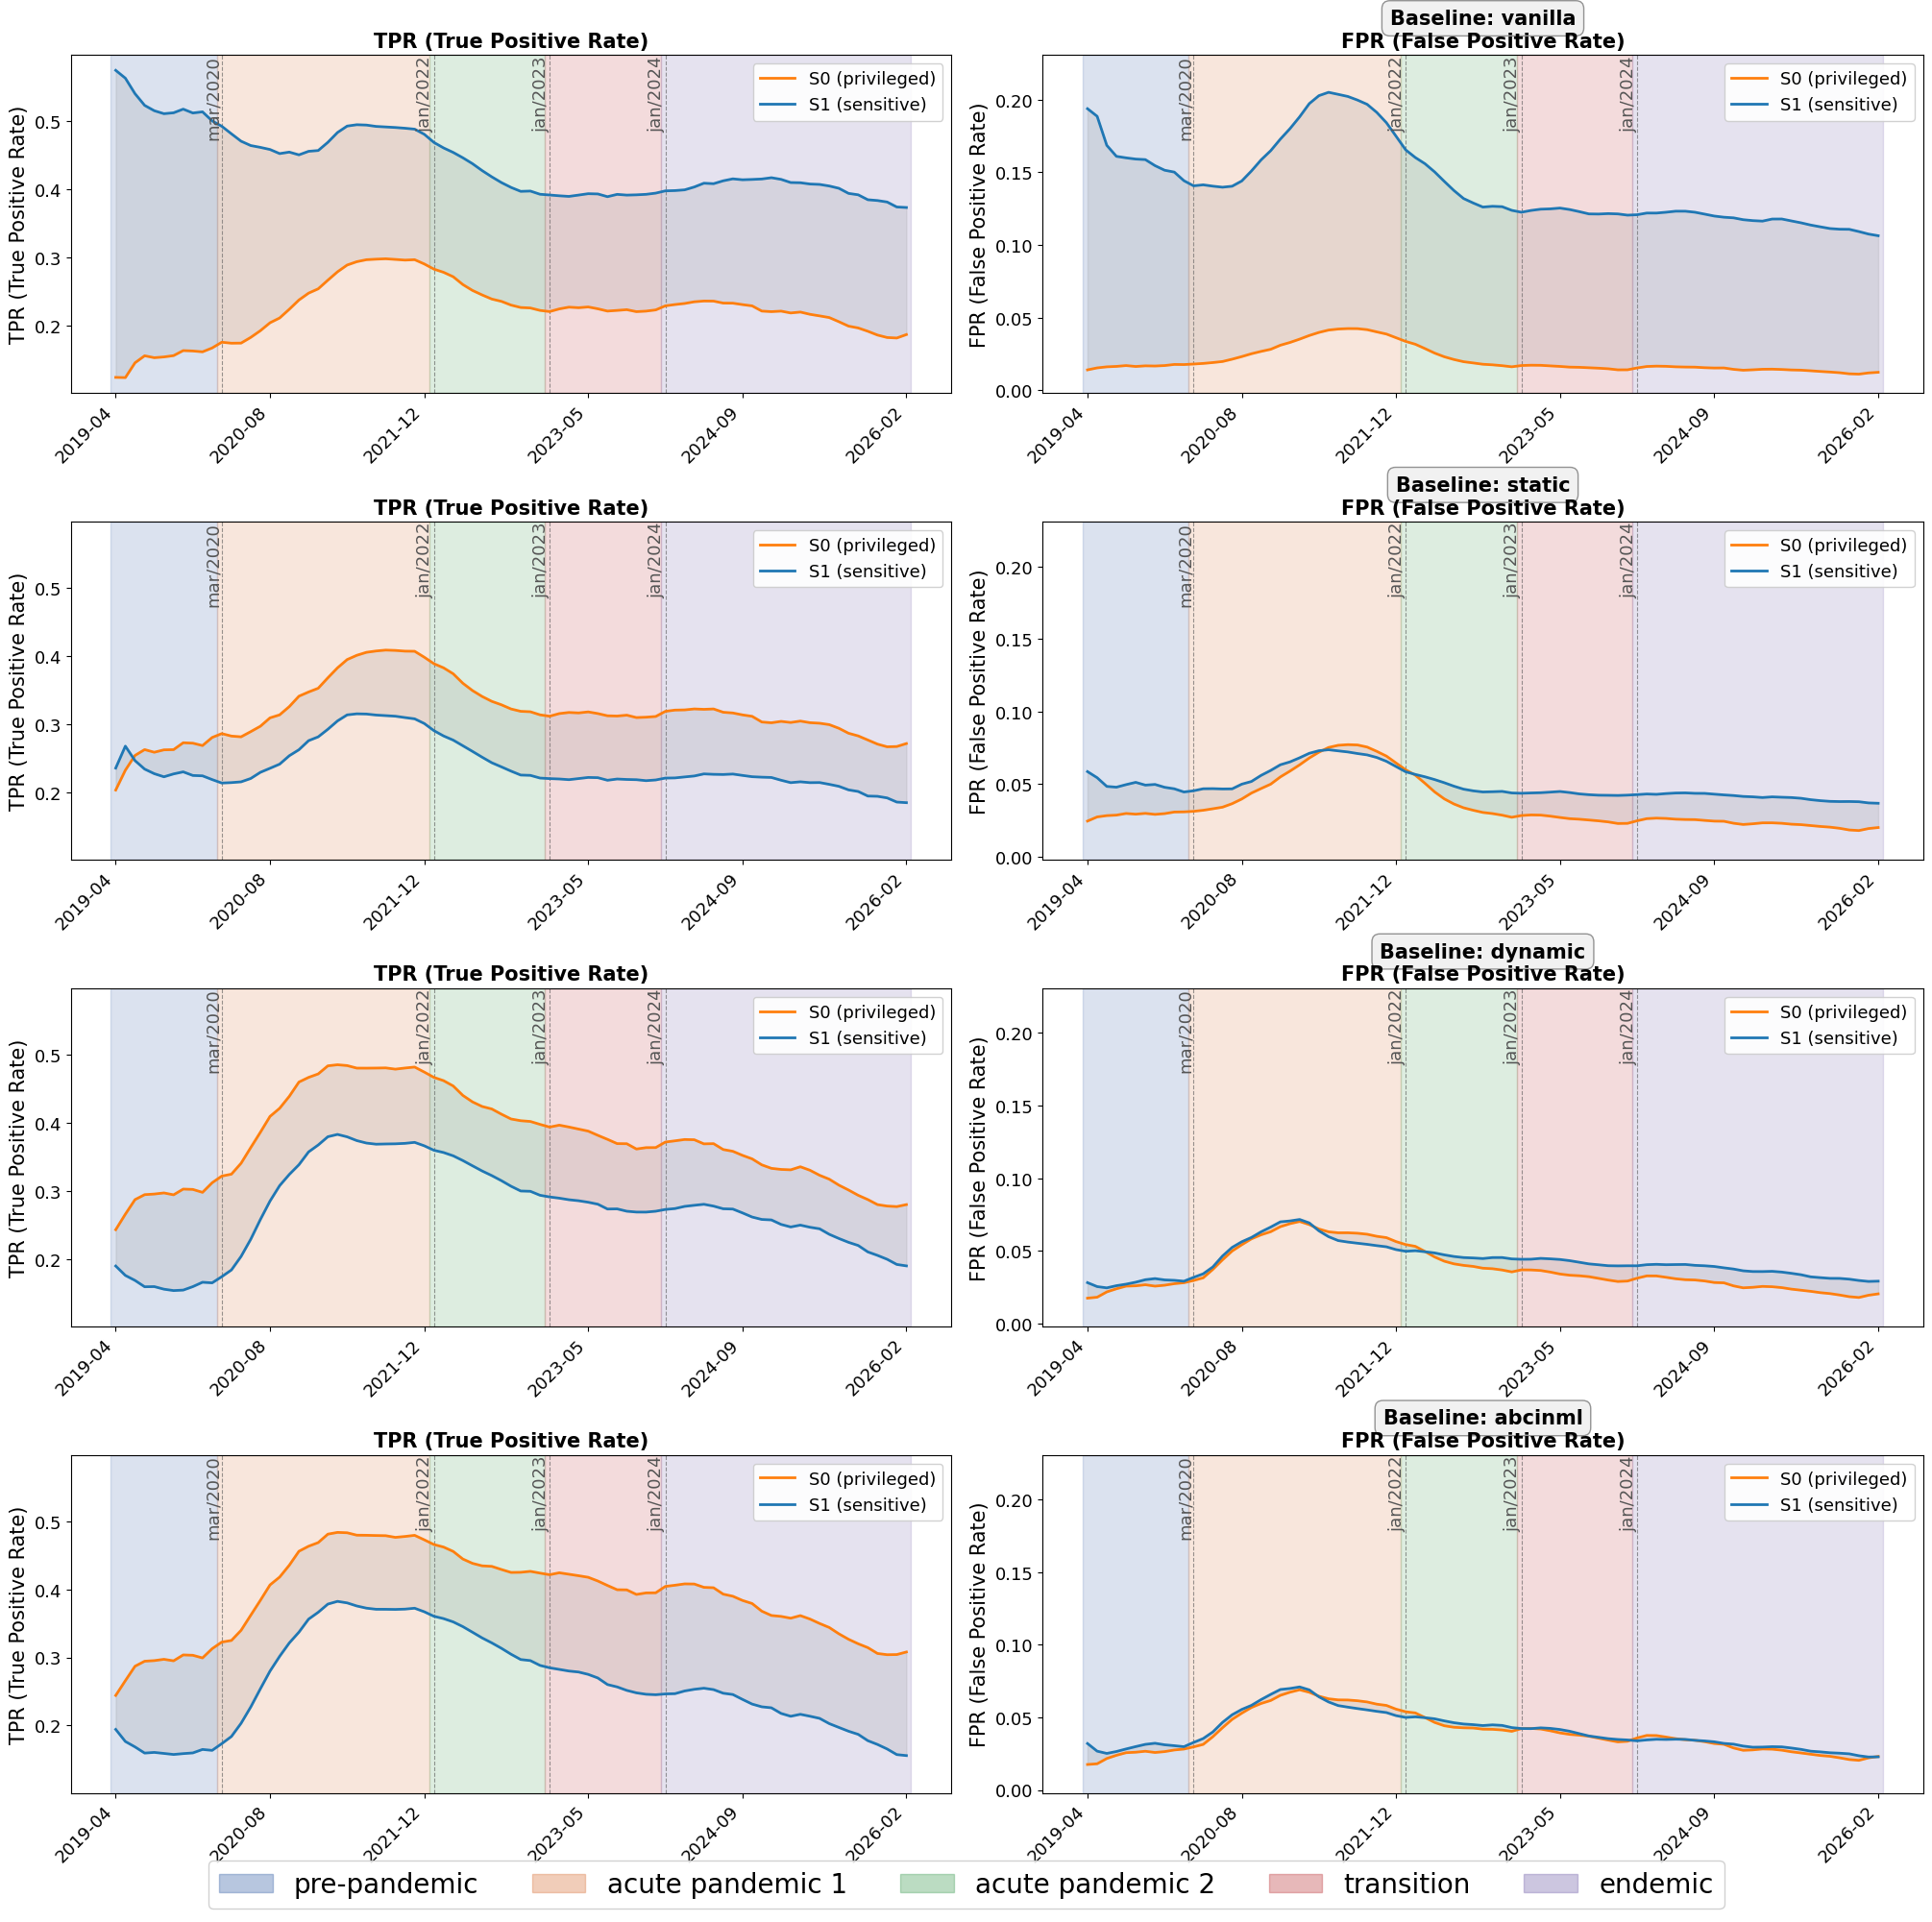

In [7]:
plot_absolute_rates('logistic_regression')

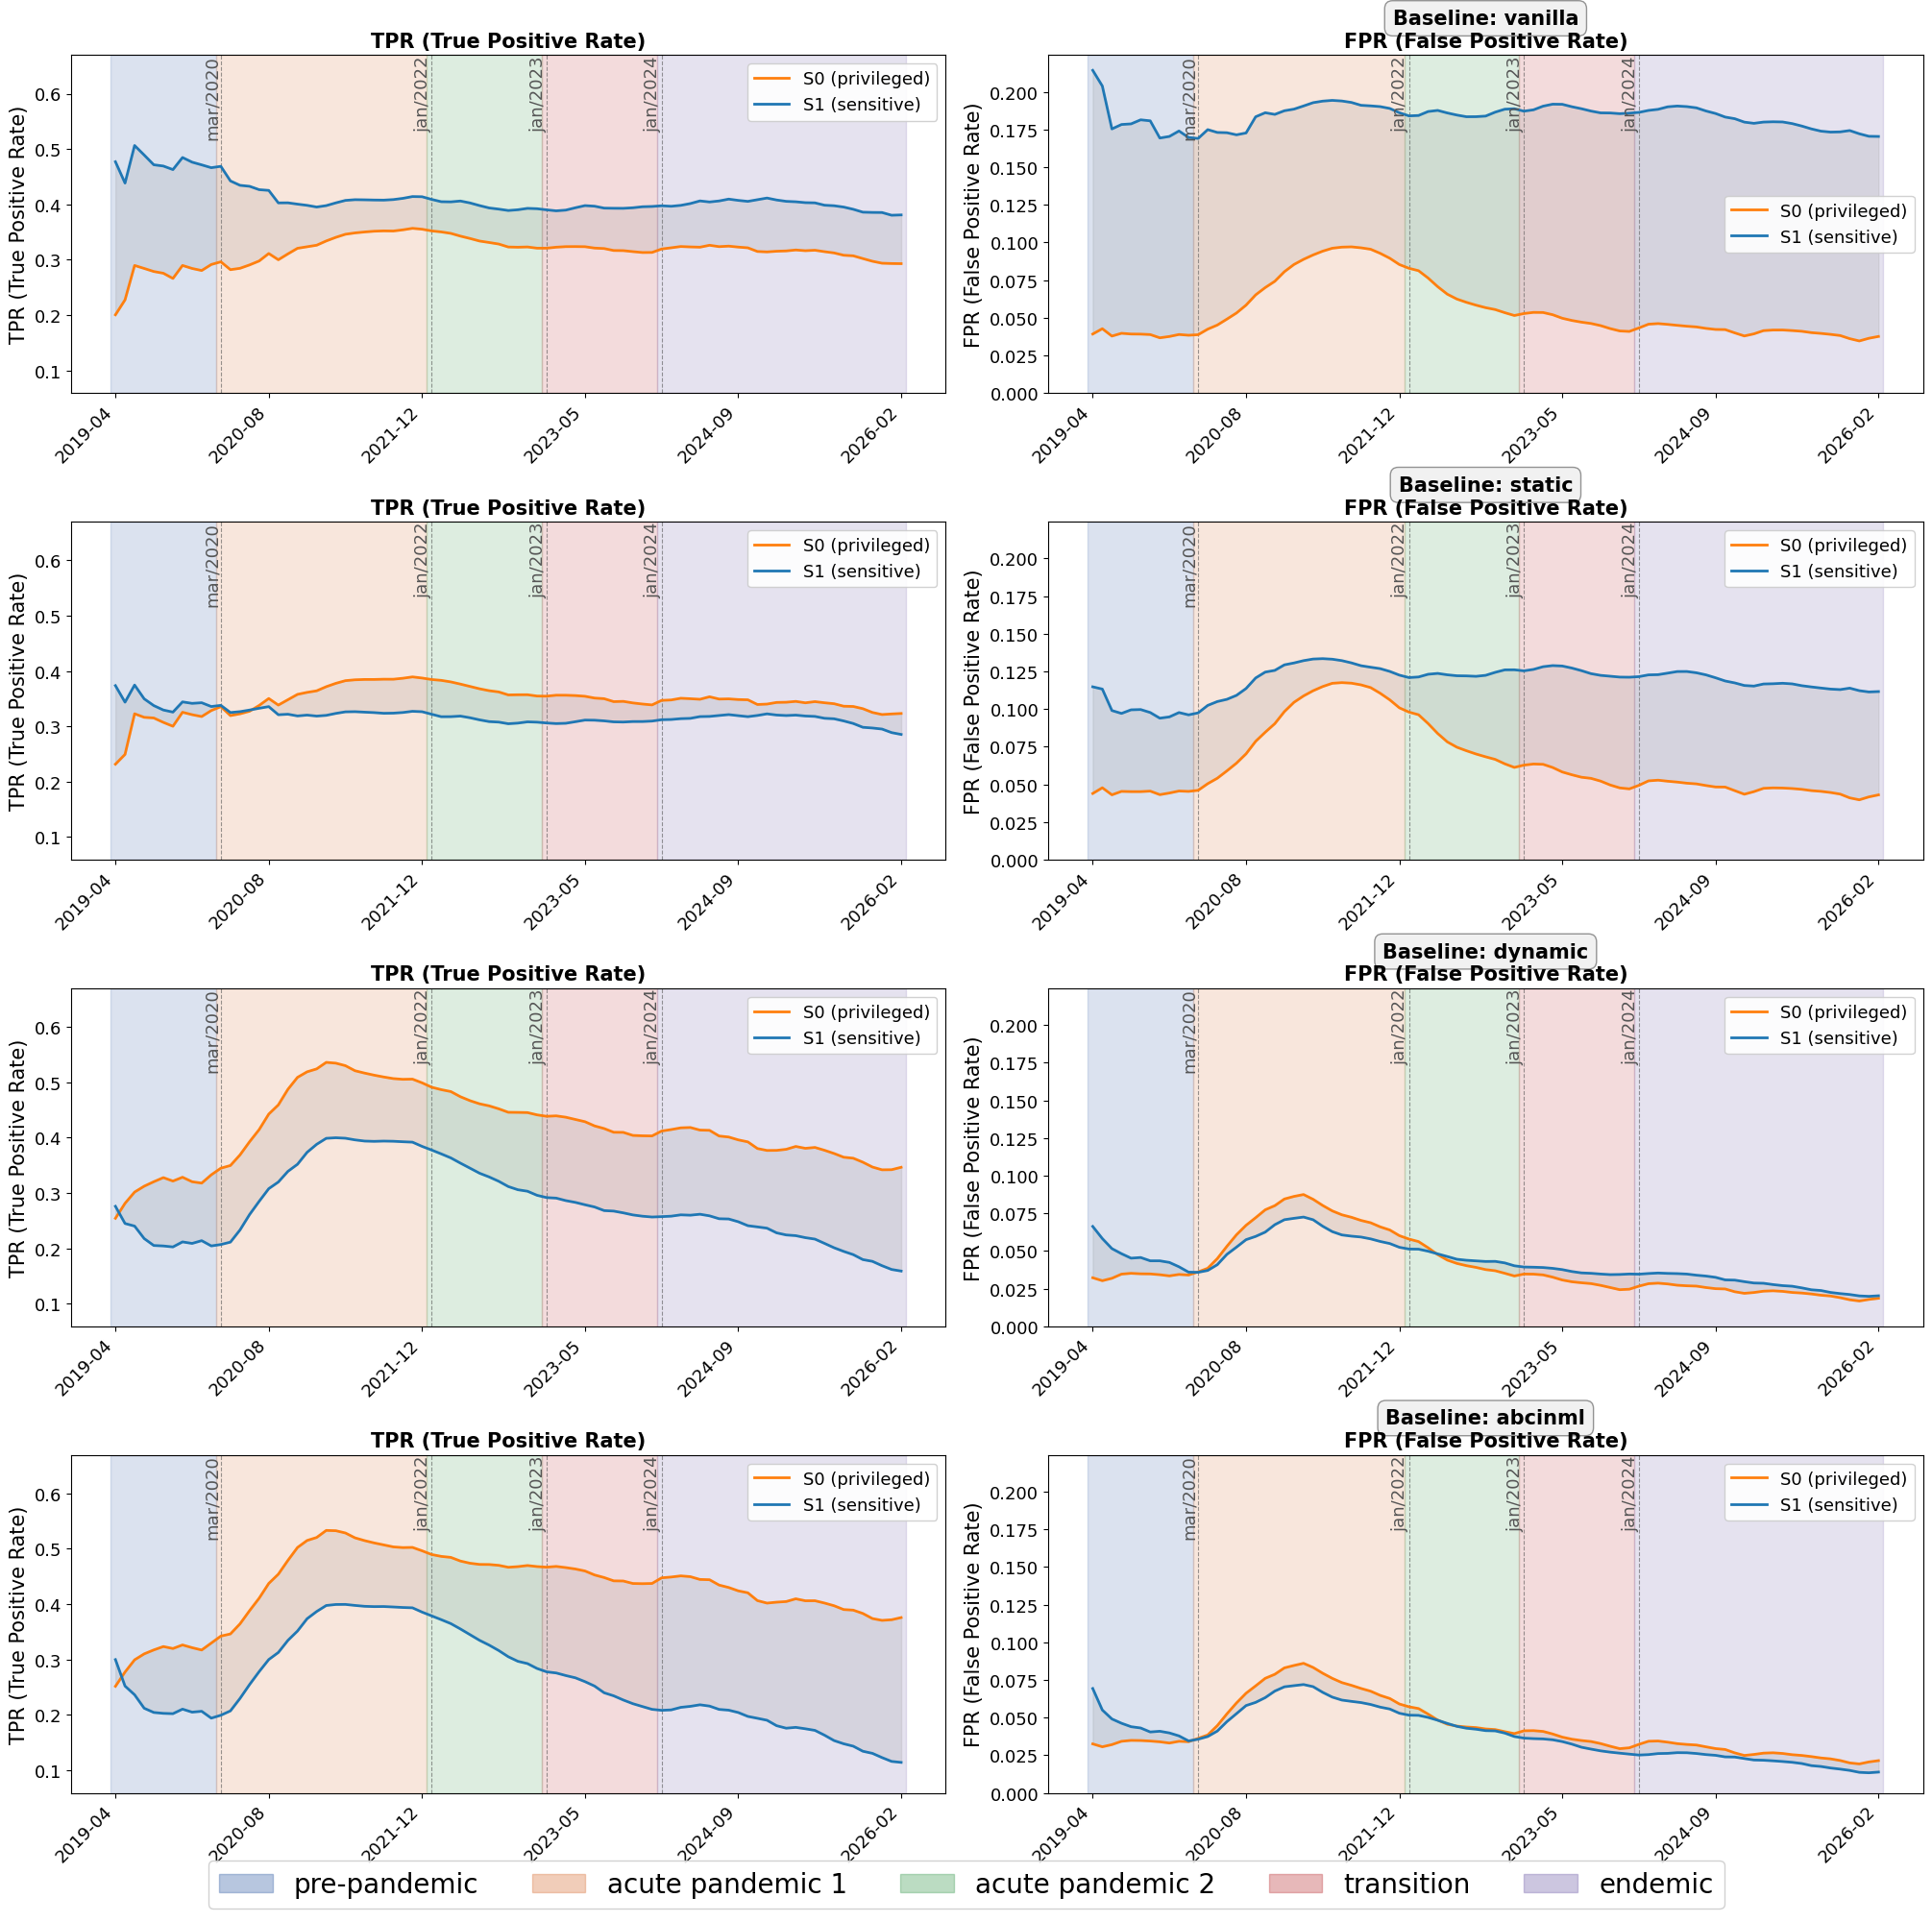

In [8]:
plot_absolute_rates('xgboost')

## Pivot table — mean TPR/FPR per baseline and group

Compact version of the absolute rates chart. For each model, one image with two stacked pivots (monthly on top, weekly below): rows = baseline, columns = (TPR/FPR) × (S0/S1), mean over the batches, in %.

In [9]:
def absolute_rates_pivot(model_name, batch_type, as_percent=True):
    """Pivot: rows = baseline, columns = (TPR/FPR) × (S0/S1), mean over the batches."""
    sub = absolute_df[
        (absolute_df['model_name'] == model_name)
        & (absolute_df['batch_type'] == batch_type)
    ]
    # mean per (baseline, batch), then mean over the batches
    per_batch = sub.groupby(['baseline', 'batch'], as_index=False)[rate_cols].mean()
    agg = (
        per_batch.groupby('baseline')[rate_cols].mean()
        .reindex([b for b in _BASELINE_ORDER if b in per_batch['baseline'].unique()])
    )
    piv = pd.DataFrame({
        ('TPR', 'S0 (privileged)'): agg['tpr_S0'],
        ('TPR', 'S1 (sensitive)'): agg['tpr_S1'],
        ('FPR', 'S0 (privileged)'): agg['fpr_S0'],
        ('FPR', 'S1 (sensitive)'): agg['fpr_S1'],
    })
    piv.columns = pd.MultiIndex.from_tuples(piv.columns, names=['Metric', 'Group'])
    piv.index.name = 'Baseline'
    if as_percent:
        piv = piv * 100
    return piv.round(2)


def _draw_pivot_table(ax, piv, subtitle):
    """Draw a pivot (2-level MultiIndex columns) as a table on an axis, with a subtitle."""
    ax.axis('off')
    ax.set_title(subtitle, fontsize=16, fontweight='bold', pad=12)

    header_metric = [''] + [m for m, _ in piv.columns]           # row 1: TPR/FPR
    header_group = ['Baseline'] + [g for _, g in piv.columns]    # row 2: Baseline / S0 / S1
    body = [[idx] + [f'{v:.2f}%' for v in row] for idx, row in zip(piv.index, piv.values)]
    table_data = [header_metric, header_group] + body

    tbl = ax.table(cellText=table_data, cellLoc='center', loc='center')
    tbl.auto_set_font_size(False)
    tbl.set_fontsize(15)
    tbl.scale(1, 2.2)

    metric_fill = {'TPR': '#dbe9f6', 'FPR': '#fbe3d6'}
    light_gray = '#f5f5f5'
    for (r, c), cell in tbl.get_celld().items():
        cell.set_edgecolor('#bbbbbb')
        if r == 0:  # metric row: TPR/FPR in bold
            txt = cell.get_text().get_text()
            cell.set_facecolor(metric_fill.get(txt, 'white'))
            if txt:
                cell.get_text().set_fontweight('bold')
            if c == 0:
                cell.set_facecolor('white')
                cell.visible_edges = 'BR'
        elif r == 1:  # header: only 'Baseline' in bold; groups normal, light gray background
            cell.set_facecolor(light_gray)
            if c == 0:
                cell.get_text().set_fontweight('bold')
        elif c == 0:  # baseline column (values): light gray background, no bold
            cell.set_facecolor(light_gray)


def save_pivot_image(model_name):
    """One image with two stacked pivots: monthly (top) and weekly (bottom)."""
    piv_monthly = absolute_rates_pivot(model_name, 'monthly')
    piv_weekly = absolute_rates_pivot(model_name, 'weekly')
    n_rows, n_cols = piv_monthly.shape
    width = 1.9 * (n_cols + 1) + 1.5
    fig, axes = plt.subplots(2, 1, figsize=(width, 2 * (0.5 * (n_rows + 2) + 0.5)))

    _draw_pivot_table(axes[0], piv_monthly, 'batch type = monthly')
    _draw_pivot_table(axes[1], piv_weekly, 'batch type = weekly')

    out_path = fig_dir / f'absolute_rates_pivot_{MODEL_ABBR[model_name]}.png'
    fig.savefig(out_path, dpi=120, bbox_inches='tight', pad_inches=0.05)
    plt.show()

In [10]:
def pivot_table_latex(model_name, model_label, label):
    """TPR/FPR pivot in LaTeX (booktabs), same style as temporal_table_latex; monthly and weekly blocks."""
    lines = [
        r'\begin{table}',
        rf'  \caption{{Mean TPR and FPR by Baseline and Group - {model_label}.}}',
        rf'  \label{{{label}}}',
        r'  \begin{tabular}{lrrrr}',
        r'    \toprule',
        r'     & \multicolumn{2}{c}{TPR} & \multicolumn{2}{c}{FPR} \\',
        r'    \cmidrule(lr){2-3} \cmidrule(lr){4-5}',
        r'    Baseline & S0 (privileged) & S1 (sensitive) & S0 (privileged) & S1 (sensitive) \\',
    ]
    for batch_type in ('monthly', 'weekly'):
        piv = absolute_rates_pivot(model_name, batch_type)
        lines += [
            r'    \midrule',
            rf'    \multicolumn{{5}}{{c}}{{\textit{{batch type = {batch_type}}}}} \\',
            r'    \midrule',
        ]
        for baseline, row in zip(piv.index, piv.values):
            lines.append(f'    {baseline} & ' + ' & '.join(rf'{v:.2f}\%' for v in row) + r' \\')
    lines += [r'    \bottomrule', r'  \end{tabular}', r'\end{table}']
    out_path = fig_dir / f'absolute_rates_pivot_{MODEL_ABBR[model_name]}.tex'
    out_path.write_text('\n'.join(lines) + '\n', encoding='utf-8')
    return '\n'.join(lines)

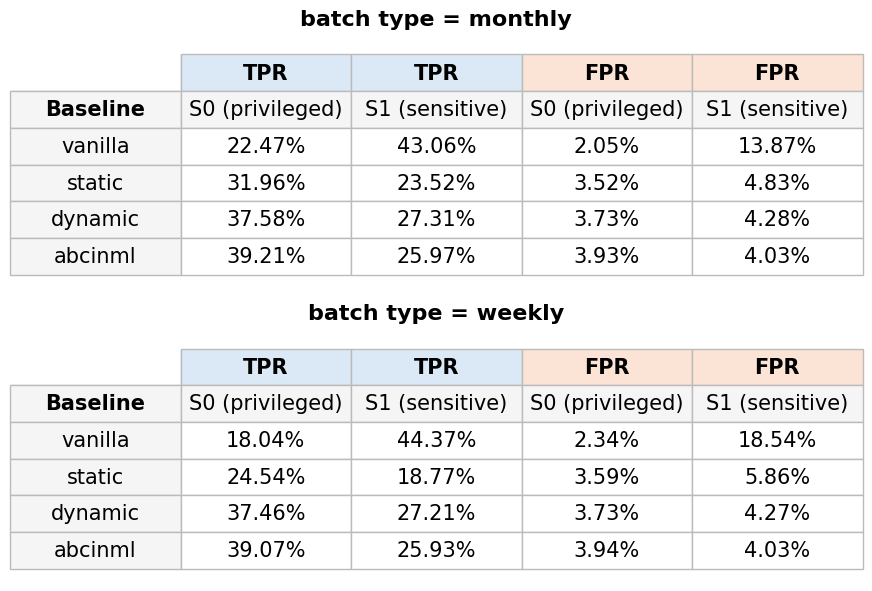

\begin{table}
  \caption{Mean TPR and FPR by Baseline and Group - Logistic Regression.}
  \label{tab:absolute-rates-lr}
  \begin{tabular}{lrrrr}
    \toprule
     & \multicolumn{2}{c}{TPR} & \multicolumn{2}{c}{FPR} \\
    \cmidrule(lr){2-3} \cmidrule(lr){4-5}
    Baseline & S0 (privileged) & S1 (sensitive) & S0 (privileged) & S1 (sensitive) \\
    \midrule
    \multicolumn{5}{c}{\textit{batch type = monthly}} \\
    \midrule
    vanilla & 22.47\% & 43.06\% & 2.05\% & 13.87\% \\
    static & 31.96\% & 23.52\% & 3.52\% & 4.83\% \\
    dynamic & 37.58\% & 27.31\% & 3.73\% & 4.28\% \\
    abcinml & 39.21\% & 25.97\% & 3.93\% & 4.03\% \\
    \midrule
    \multicolumn{5}{c}{\textit{batch type = weekly}} \\
    \midrule
    vanilla & 18.04\% & 44.37\% & 2.34\% & 18.54\% \\
    static & 24.54\% & 18.77\% & 3.59\% & 5.86\% \\
    dynamic & 37.46\% & 27.21\% & 3.73\% & 4.27\% \\
    abcinml & 39.07\% & 25.93\% & 3.94\% & 4.03\% \\
    \bottomrule
  \end{tabular}
\end{table}


Metric               TPR                            FPR               
Group    S0 (privileged) S1 (sensitive) S0 (privileged) S1 (sensitive)
Baseline                                                              
vanilla            22.47          43.06            2.05          13.87
static             31.96          23.52            3.52           4.83
dynamic            37.58          27.31            3.73           4.28
abcinml            39.21          25.97            3.93           4.03

In [11]:
save_pivot_image('logistic_regression')
print(pivot_table_latex('logistic_regression', 'Logistic Regression', 'tab:absolute-rates-lr'))
absolute_rates_pivot('logistic_regression', 'monthly')

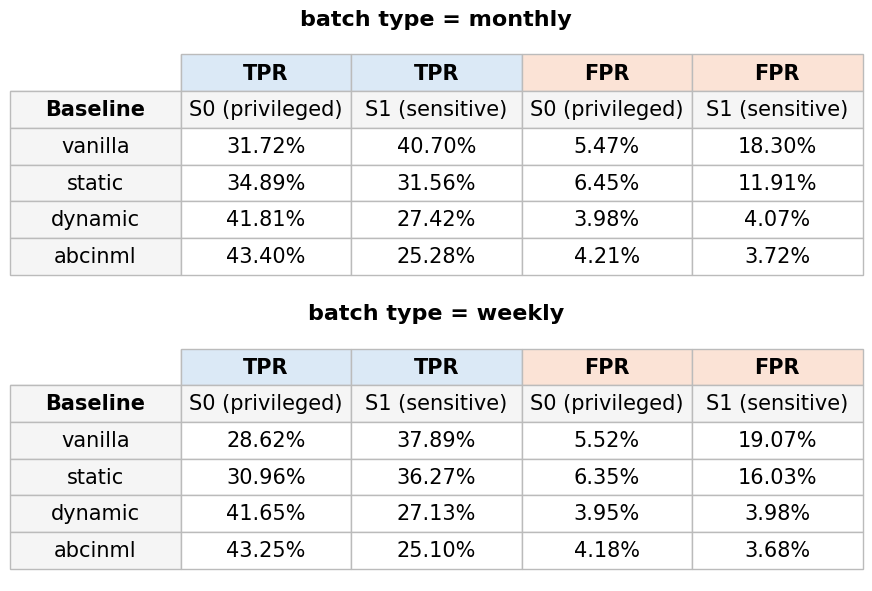

\begin{table}
  \caption{Mean TPR and FPR by Baseline and Group - XGBoost.}
  \label{tab:absolute-rates-xgboost}
  \begin{tabular}{lrrrr}
    \toprule
     & \multicolumn{2}{c}{TPR} & \multicolumn{2}{c}{FPR} \\
    \cmidrule(lr){2-3} \cmidrule(lr){4-5}
    Baseline & S0 (privileged) & S1 (sensitive) & S0 (privileged) & S1 (sensitive) \\
    \midrule
    \multicolumn{5}{c}{\textit{batch type = monthly}} \\
    \midrule
    vanilla & 31.72\% & 40.70\% & 5.47\% & 18.30\% \\
    static & 34.89\% & 31.56\% & 6.45\% & 11.91\% \\
    dynamic & 41.81\% & 27.42\% & 3.98\% & 4.07\% \\
    abcinml & 43.40\% & 25.28\% & 4.21\% & 3.72\% \\
    \midrule
    \multicolumn{5}{c}{\textit{batch type = weekly}} \\
    \midrule
    vanilla & 28.62\% & 37.89\% & 5.52\% & 19.07\% \\
    static & 30.96\% & 36.27\% & 6.35\% & 16.03\% \\
    dynamic & 41.65\% & 27.13\% & 3.95\% & 3.98\% \\
    abcinml & 43.25\% & 25.10\% & 4.18\% & 3.68\% \\
    \bottomrule
  \end{tabular}
\end{table}


Metric               TPR                            FPR               
Group    S0 (privileged) S1 (sensitive) S0 (privileged) S1 (sensitive)
Baseline                                                              
vanilla            31.72          40.70            5.47          18.30
static             34.89          31.56            6.45          11.91
dynamic            41.81          27.42            3.98           4.07
abcinml            43.40          25.28            4.21           3.72

In [12]:
save_pivot_image('xgboost')
print(pivot_table_latex('xgboost', 'XGBoost', 'tab:absolute-rates-xgboost'))
absolute_rates_pivot('xgboost', 'monthly')

## Table — temporal metrics per baseline

For section 4.2 of the paper (LR), in the format of Table 3: rows = baselines, columns = the three temporal
metrics of `temporal_results_df.csv`, monthly and weekly blocks. All three are computed on the DP Diff. series
of each run, and for all of them lower is better:
- **Maximum Bias** = max |DP_t|;
- **Temporal Stability** = mean of |DP_t − DP_{t−1}|;
- **Maximum Bias Difference** = max |DP_t − DP_{t−1}|.

`abcinml` is the mean over the 11 alphas, the same convention as Table 3.

**One forecast window per block.** The window sets the warm-up, so it changes the batch where the model starts
training and the start of the evaluated series, including for vanilla/static. For weekly LR, the Maximum Bias of static goes from
10.34% (window 3) to 18.12% (window 5). That is why each block uses a single window in which all four baselines
exist: **monthly = 3** and **weekly = 5** (weekly is missing the window-3 dynamic).

In [13]:
TEMPORAL_METRICS = ['Maximum Bias', 'Temporal Stability', 'Maximum Bias Difference']
# LaTeX headers: ↓ = lower is better, ↑ = higher is better (all three temporal metrics are ↓)
TEMPORAL_HEADERS = [r'Max. Bias $\downarrow$', r'Temporal Stability $\downarrow$', r'Max. Bias Diff. $\downarrow$']
TABLE_WINDOW = {'monthly': 3, 'weekly': 5}  # only window with all 4 baselines for each batch_type
temporal_table_df = load_filtered('temporal_results_df.csv')


def temporal_metrics_table(model_name, batch_type, as_percent=True):
    """Rows = baseline, columns = temporal metrics; abcinml = mean over the alphas."""
    fw = TABLE_WINDOW[batch_type]
    sub = temporal_table_df[
        (temporal_table_df['model_name'] == model_name)
        & (temporal_table_df['batch_type'] == batch_type)
        & (temporal_table_df['forecast_window'] == fw)
    ]
    missing = [b for b in _BASELINE_ORDER if b not in sub['baseline'].unique()]
    assert not missing, f'{model_name} {batch_type} fw={fw}: faltam {missing}'
    tbl = sub.groupby('baseline')[TEMPORAL_METRICS].mean().reindex(_BASELINE_ORDER)
    tbl.index.name = 'Baseline'
    return (tbl * 100 if as_percent else tbl).round(2)


def temporal_table_latex(model_name, model_label, label):
    """Table in the style of Table 3 of the paper (booktabs), with the best value of each column in bold."""
    header = ' & '.join(['Baseline', *TEMPORAL_HEADERS])
    lines = [
        r'\begin{table}',
        rf'  \caption{{Temporal Fairness Metrics by Baseline - {model_label}.}}',
        rf'  \label{{{label}}}',
        r'  \begin{tabular}{lrrr}',
        r'    \toprule',
        rf'    {header} \\',
    ]
    for batch_type in ('monthly', 'weekly'):
        tbl = temporal_metrics_table(model_name, batch_type)
        lines += [
            r'    \midrule',
            rf'    \multicolumn{{4}}{{c}}{{\textit{{batch type = {batch_type}, forecast window = {TABLE_WINDOW[batch_type]}}}}} \\',
            r'    \midrule',
        ]
        for baseline, row in tbl.iterrows():
            cells = [
                rf'\textbf{{{v:.2f}\%}}' if v == tbl[col].min() else rf'{v:.2f}\%'
                for col, v in row.items()
            ]
            lines.append(f'    {baseline} & ' + ' & '.join(cells) + r' \\')
    lines += [r'    \bottomrule', r'  \end{tabular}', r'\end{table}']
    out_path = fig_dir / f'temporal_metrics_{MODEL_ABBR[model_name]}.tex'
    out_path.write_text('\n'.join(lines) + '\n', encoding='utf-8')
    return '\n'.join(lines)


pd.concat({bt: temporal_metrics_table('logistic_regression', bt) for bt in ('monthly', 'weekly')})

Maximum Bias  Temporal Stability  Maximum Bias Difference
        Baseline                                                           
monthly vanilla          33.73                1.29                     7.66
        static           10.10                1.14                     6.19
        dynamic           8.25                0.99                     4.78
        abcinml           9.13                1.17                     5.00
weekly  vanilla          36.42                1.95                    24.94
        static           18.12                1.55                    10.99
        dynamic          10.97                1.13                     8.14
        abcinml           9.95                1.12                     8.65

In [14]:
print(temporal_table_latex('logistic_regression', 'Logistic Regression', 'tab:temporal-lr'))

\begin{table}
  \caption{Temporal Fairness Metrics by Baseline - Logistic Regression.}
  \label{tab:temporal-lr}
  \begin{tabular}{lrrr}
    \toprule
    Baseline & Max. Bias $\downarrow$ & Temporal Stability $\downarrow$ & Max. Bias Diff. $\downarrow$ \\
    \midrule
    \multicolumn{4}{c}{\textit{batch type = monthly, forecast window = 3}} \\
    \midrule
    vanilla & 33.73\% & 1.29\% & 7.66\% \\
    static & 10.10\% & 1.14\% & 6.19\% \\
    dynamic & \textbf{8.25\%} & \textbf{0.99\%} & \textbf{4.78\%} \\
    abcinml & 9.13\% & 1.17\% & 5.00\% \\
    \midrule
    \multicolumn{4}{c}{\textit{batch type = weekly, forecast window = 5}} \\
    \midrule
    vanilla & 36.42\% & 1.95\% & 24.94\% \\
    static & 18.12\% & 1.55\% & 10.99\% \\
    dynamic & 10.97\% & 1.13\% & \textbf{8.14\%} \\
    abcinml & \textbf{9.95\%} & \textbf{1.12\%} & 8.65\% \\
    \bottomrule
  \end{tabular}
\end{table}


## Table — ABCInML temporal metrics per model

Same format as the previous table, but the rows are the models and every row is `abcinml` (mean over the
11 alphas). Same forecast windows per block (**monthly = 3**, **weekly = 5**), so the Logistic
Regression row matches the `abcinml` row of the previous table. LightGBM is left out: it only has monthly with window 3.

In [15]:
ABC_TABLE_MODELS = {
    'logistic_regression': 'Logistic Regression',
    'xgboost': 'XGBoost',
    'random_forest': 'Random Forest',
}
abc_temporal_df = load_filtered('temporal_results_df.csv', list(ABC_TABLE_MODELS))


def abcinml_models_table(batch_type, as_percent=True):
    """Rows = model, columns = abcinml temporal metrics (mean over the alphas)."""
    fw = TABLE_WINDOW[batch_type]
    sub = abc_temporal_df[
        (abc_temporal_df['baseline'] == 'abcinml')
        & (abc_temporal_df['batch_type'] == batch_type)
        & (abc_temporal_df['forecast_window'] == fw)
    ]
    n_alphas = sub.groupby('model_name')['alpha'].nunique().reindex(list(ABC_TABLE_MODELS))
    incomplete = n_alphas[n_alphas != 11]
    assert incomplete.empty, f'{batch_type} fw={fw}: alphas incompletos {incomplete.to_dict()}'
    tbl = sub.groupby('model_name')[TEMPORAL_METRICS].mean().reindex(list(ABC_TABLE_MODELS))
    tbl.index = [ABC_TABLE_MODELS[m] for m in tbl.index]
    tbl.index.name = 'Model'
    return (tbl * 100 if as_percent else tbl).round(2)


def abcinml_models_latex(label='tab:temporal-abcinml-models'):
    """Table in the style of Table 3 of the paper (booktabs), with the best value of each column in bold."""
    header = ' & '.join(['Model', *TEMPORAL_HEADERS])
    lines = [
        r'\begin{table}',
        r'  \caption{Temporal Fairness Metrics of ABCInML by Model.}',
        rf'  \label{{{label}}}',
        r'  \begin{tabular}{lrrr}',
        r'    \toprule',
        rf'    {header} \\',
    ]
    for batch_type in ('monthly', 'weekly'):
        tbl = abcinml_models_table(batch_type)
        lines += [
            r'    \midrule',
            rf'    \multicolumn{{4}}{{c}}{{\textit{{batch type = {batch_type}, forecast window = {TABLE_WINDOW[batch_type]}}}}} \\',
            r'    \midrule',
        ]
        for model, row in tbl.iterrows():
            cells = [
                rf'\textbf{{{v:.2f}\%}}' if v == tbl[col].min() else rf'{v:.2f}\%'
                for col, v in row.items()
            ]
            lines.append(f'    {model} & ' + ' & '.join(cells) + r' \\')
    lines += [r'    \bottomrule', r'  \end{tabular}', r'\end{table}']
    out_path = fig_dir / 'temporal_metrics_abcinml_models.tex'
    out_path.write_text('\n'.join(lines) + '\n', encoding='utf-8')
    return '\n'.join(lines)


pd.concat({bt: abcinml_models_table(bt) for bt in ('monthly', 'weekly')})

Maximum Bias  Temporal Stability  \
        Model                                                   
monthly Logistic Regression          9.13                1.17   
        XGBoost                      9.15                1.26   
        Random Forest                7.58                0.80   
weekly  Logistic Regression          9.95                1.12   
        XGBoost                     14.40                1.04   
        Random Forest                7.13                0.74   

                             Maximum Bias Difference  
        Model                                         
monthly Logistic Regression                     5.00  
        XGBoost                                 6.06  
        Random Forest                           2.98  
weekly  Logistic Regression                     8.65  
        XGBoost                                10.94  
        Random Forest                           4.86

In [16]:
print(abcinml_models_latex())

\begin{table}
  \caption{Temporal Fairness Metrics of ABCInML by Model.}
  \label{tab:temporal-abcinml-models}
  \begin{tabular}{lrrr}
    \toprule
    Model & Max. Bias $\downarrow$ & Temporal Stability $\downarrow$ & Max. Bias Diff. $\downarrow$ \\
    \midrule
    \multicolumn{4}{c}{\textit{batch type = monthly, forecast window = 3}} \\
    \midrule
    Logistic Regression & 9.13\% & 1.17\% & 5.00\% \\
    XGBoost & 9.15\% & 1.26\% & 6.06\% \\
    Random Forest & \textbf{7.58\%} & \textbf{0.80\%} & \textbf{2.98\%} \\
    \midrule
    \multicolumn{4}{c}{\textit{batch type = weekly, forecast window = 5}} \\
    \midrule
    Logistic Regression & 9.95\% & 1.12\% & 8.65\% \\
    XGBoost & 14.40\% & 1.04\% & 10.94\% \\
    Random Forest & \textbf{7.13\%} & \textbf{0.74\%} & \textbf{4.86\%} \\
    \bottomrule
  \end{tabular}
\end{table}


## Accuracy × metric frontier — LR vs. XGBoost vs. Random Forest (varying alpha)

Each point is one `alpha` value of `abcinml`: mean accuracy (x axis) and mean metric (y axis) over all batches (and forecast windows) of that alpha. One figure per `batch_type` and per y-axis metric (DP, TPR and FPR Diff., AUC). The ends α = 0 (pure anticipation) and α = 1 (equivalent to dynamic) are labeled.

The arrows next to the axes point to where the metric is better: higher for accuracy/AUC; closer to zero for the group differences.

**Random Forest (partial results):** for now it only has `forecast_window = 3`, while LR and XGBoost average 3, 5 and 10. Restricting LR/XGBoost to `fw = 3` moves their points by at most ~0.15 pp, so the comparison holds, but the RF points will still change once windows 5 and 10 are run.

In [17]:
import matplotlib.transforms as mtransforms
from matplotlib.lines import Line2D
from matplotlib.textpath import TextPath

# RF only enters the frontiers; MODELS (LR/XGBoost) still applies to the previous charts
FRONTIER_MODELS = MODELS + ['random_forest']
frontier_df = load_filtered('assessment_all_baselines.csv', FRONTIER_MODELS)

MODEL_COLORS = {'logistic_regression': '#1f77b4', 'xgboost': '#d62728', 'random_forest': '#2ca02c'}
MODEL_MARKERS = {'logistic_regression': 'o', 'xgboost': 's', 'random_forest': '^'}
MODEL_LABELS = {'logistic_regression': 'Logistic Regression', 'xgboost': 'XGBoost', 'random_forest': 'Random Forest'}
LABEL_LANES = {'logistic_regression': (-9, 'right'), 'random_forest': (9, 'left'), 'xgboost': (62, 'left')}
METRIC_LABELS = dict(_SNAPSHOT_METRICS)
HIGHER_IS_BETTER = {'acc', 'auc'}  # other metrics: group differences, better near 0


def frontier_points(model_name, batch_type, metric):
    """Mean accuracy and mean metric (in %) per alpha, abcinml only."""
    abc = frontier_df[
        (frontier_df['model_name'] == model_name)
        & (frontier_df['batch_type'] == batch_type)
        & (frontier_df['baseline'] == 'abcinml')
    ]
    return abc.groupby('alpha')[['acc', metric]].mean().sort_index() * 100


def _underline(ax, xy, dx, dy, ha, text, color, fontsize=12):
    """Underline, in the model color, a label placed (dx, dy) points away from point xy (in data units)."""
    width = TextPath((0, 0), text, size=fontsize).get_extents().width  # in points
    x0, x1 = (dx - width, dx) if ha == 'right' else (dx, dx + width)
    # Coordinates in points relative to the data point: follows the final savefig layout
    trans = (
        mtransforms.Affine2D().scale(1 / 72) + ax.figure.dpi_scale_trans
        + mtransforms.ScaledTranslation(*xy, ax.transData)
    )
    ax.add_artist(Line2D([x0, x1], [dy - 8, dy - 8], transform=trans, color=color, linewidth=2.2))


def _better_arrow(ax, axis, positive):
    """Arrow outside the axis pointing to where the metric improves (positive = increasing direction)."""
    style = dict(arrowstyle='-|>', color='#555555', lw=1.8, mutation_scale=16)
    text = dict(fontsize=12, color='#555555', annotation_clip=False)
    if axis == 'x':  # on the x-axis label row, to the right
        tail, head = (0.80, -0.115), (0.97, -0.115)
        if not positive:
            tail, head = head, tail
        ax.annotate('', xy=head, xytext=tail, xycoords='axes fraction', arrowprops=style, annotation_clip=False)
        ax.annotate('better', xy=(min(tail[0], head[0]) - 0.01, -0.115), xycoords='axes fraction',
                    ha='right', va='center', **text)
    else:  # to the right of the y axis, at the end where the metric improves
        tail, head = ((1.025, 0.62), (1.025, 0.98)) if positive else ((1.025, 0.38), (1.025, 0.02))
        ax.annotate('', xy=head, xytext=tail, xycoords='axes fraction', arrowprops=style, annotation_clip=False)
        ax.annotate('better', xy=(1.045, (tail[1] + head[1]) / 2), xycoords='axes fraction',
                    rotation=90, ha='left', va='center', **text)


def _draw_frontier(ax, batch_type, metric='dp', points_fn=None):
    y_values = []
    for model in FRONTIER_MODELS:
        pts = (points_fn or frontier_points)(model, batch_type, metric)
        y_values.extend(pts[metric])
        ax.scatter(
            pts['acc'], pts[metric],
            color=MODEL_COLORS[model], marker=MODEL_MARKERS[model], s=60,
            edgecolor='white', linewidth=1.0, zorder=3, label=MODEL_LABELS[model],
        )
        # Labels only at the ends: they show the direction of alpha along the frontier.
        # Each model becomes an almost vertical column (LR < XGBoost < RF in accuracy). One band of
        # labels per model: LR on the left, RF right next to its points and XGBoost in a band
        # further right, so they do not fall on the points or on the RF labels.
        dx, ha = LABEL_LANES[model]
        a0, a1 = pts.index.min(), pts.index.max()
        # Push the two labels of the same model apart vertically (avoids touching when close)
        away = 6 if pts.loc[a0, metric] >= pts.loc[a1, metric] else -6
        for alpha, dy in ((a0, away), (a1, -away)):
            text = f'α = {alpha:g}'
            xy = (pts.loc[alpha, 'acc'], pts.loc[alpha, metric])
            ax.annotate(
                text, xy, xytext=(dx, dy), textcoords='offset points', ha=ha, va='center',
                fontsize=12, color='#333333',
            )
            _underline(ax, xy, dx, dy, ha, text, MODEL_COLORS[model])

    ax.margins(y=0.08)  # room for the end labels
    ax.set_xlim(80, 90)  # fixed accuracy scale, shared by all frontiers
    label = METRIC_LABELS.get(metric, metric)
    ax.set_xlabel('Accuracy (%)', fontsize=15)
    ax.set_ylabel(f'{label} (%)', fontsize=15)
    ax.set_title(
        f'Accuracy vs. {label} across α — LR vs. XGBoost vs. RF ({batch_type} batches)',
        fontsize=15, fontweight='bold',
    )
    ax.tick_params(axis='both', labelsize=13)
    ax.grid(color='#dddddd', linewidth=0.8)
    ax.set_axisbelow(True)
    ax.legend(fontsize=13, framealpha=0.9, loc='best')

    _better_arrow(ax, 'x', positive=True)
    # Group differences improve towards zero: the direction depends on the sign of the values
    y_positive = metric in HIGHER_IS_BETTER or pd.Series(y_values).median() < 0
    _better_arrow(ax, 'y', positive=y_positive)


def _save_frontier(fig, metric, suffix):
    slug = metric.lower().replace(' ', '_')
    out_path = fig_dir / f'frontier_acc_{slug}_{suffix}.png'
    fig.savefig(out_path, dpi=120, bbox_inches='tight')
    plt.show()


def plot_frontier(batch_type, metric='dp', points_fn=None):
    fig, ax = plt.subplots(figsize=(10, 6), layout='constrained')
    _draw_frontier(ax, batch_type, metric, points_fn)
    _save_frontier(fig, metric, batch_type)


def plot_frontier_pair(metric='dp', points_fn=None):
    """The monthly and weekly charts of the metric side by side, as subplots of one figure."""
    fig, axes = plt.subplots(1, 2, figsize=(21, 6), layout='constrained')
    for ax, batch_type in zip(axes, ('monthly', 'weekly')):
        _draw_frontier(ax, batch_type, metric, points_fn)
        ax.set_title(f'{batch_type} batches', fontsize=15, fontweight='bold')  # the shared part goes in the suptitle
    label = METRIC_LABELS.get(metric, metric)
    fig.suptitle(f'Accuracy vs. {label} across α — LR vs. XGBoost vs. RF', fontsize=17, fontweight='bold')
    _save_frontier(fig, metric, 'monthly_weekly')


pd.concat({m: frontier_points(m, 'monthly', 'dp') for m in FRONTIER_MODELS}, axis=1).round(2)

logistic_regression       xgboost       random_forest      
                      acc    dp     acc    dp           acc    dp
alpha                                                            
0.0                 86.49  3.22   86.63  2.89         86.71  2.05
0.1                 86.51  3.35   86.67  2.87         86.74  2.07
0.2                 86.54  3.50   86.70  2.86         86.76  2.08
0.3                 86.56  3.65   86.74  2.92         86.78  2.16
0.4                 86.59  3.81   86.77  3.01         86.80  2.20
0.5                 86.61  3.97   86.81  3.14         86.83  2.29
0.6                 86.64  4.13   86.84  3.31         86.85  2.32
0.7                 86.66  4.29   86.87  3.50         86.87  2.41
0.8                 86.68  4.45   86.90  3.67         86.88  2.50
0.9                 86.70  4.59   86.93  3.87         86.90  2.58
1.0                 86.73  4.75   86.98  4.14         86.92  2.74

### Demographic Parity Diff.

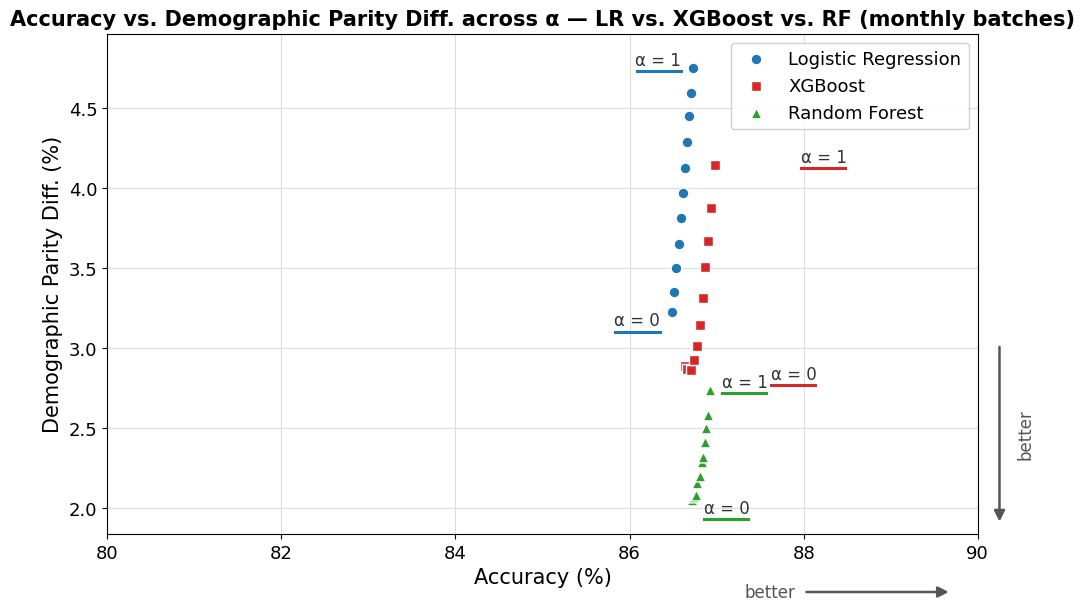

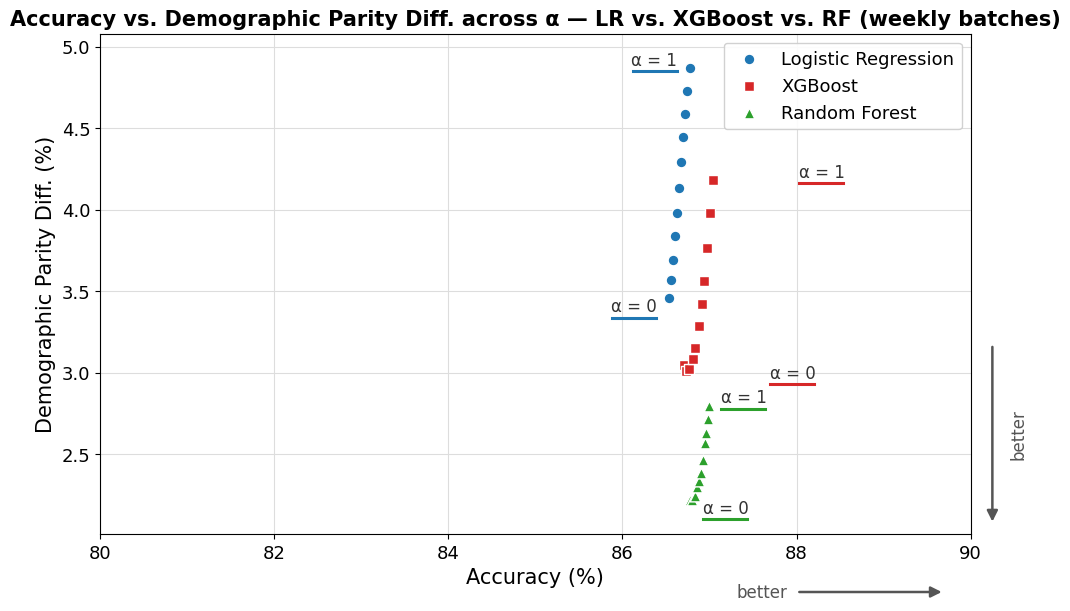

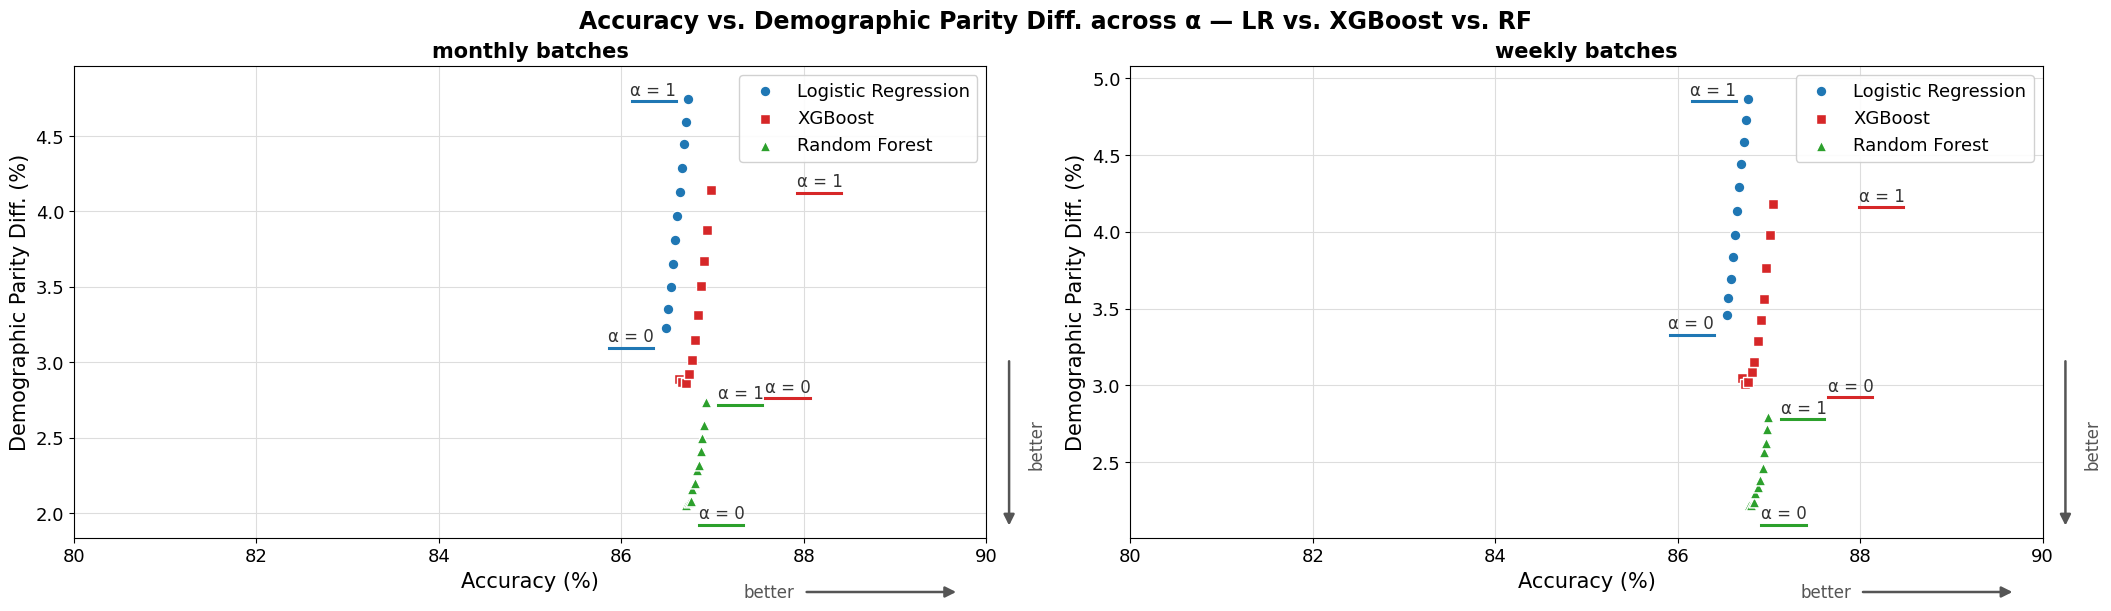

In [18]:
plot_frontier('monthly', 'dp')
plot_frontier('weekly', 'dp')
plot_frontier_pair('dp')

### TPR Difference

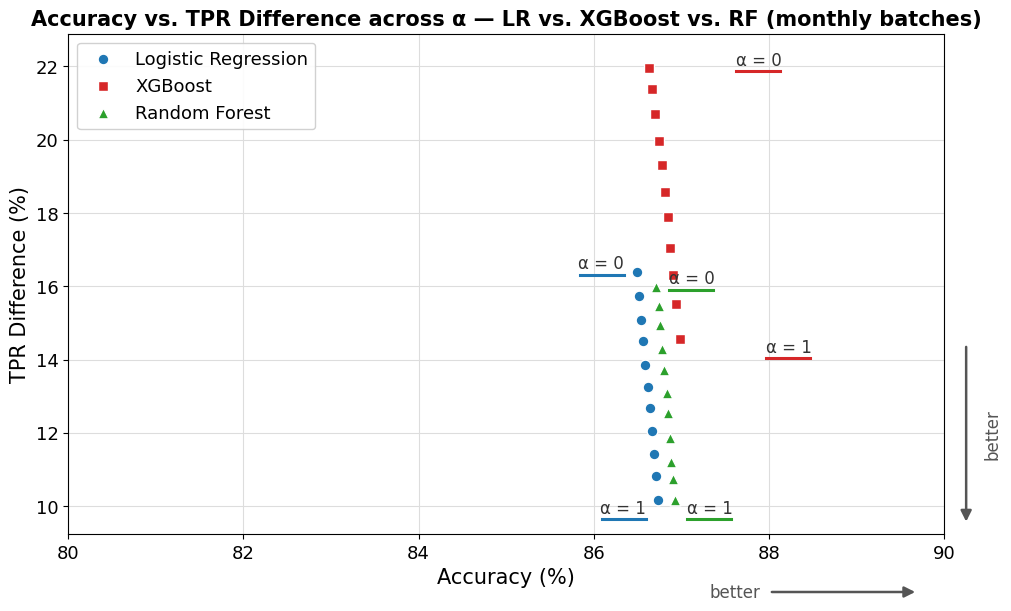

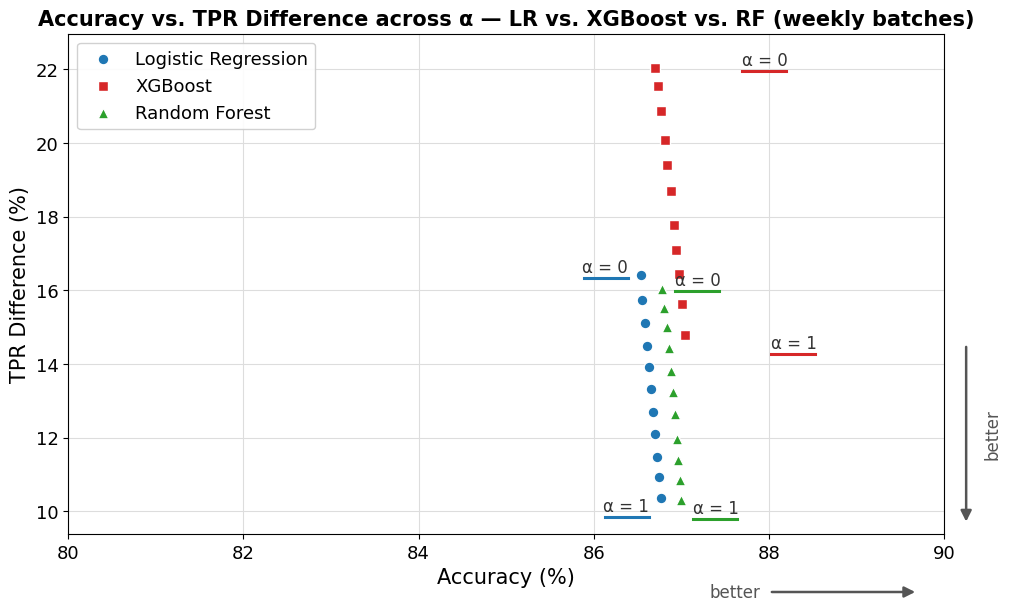

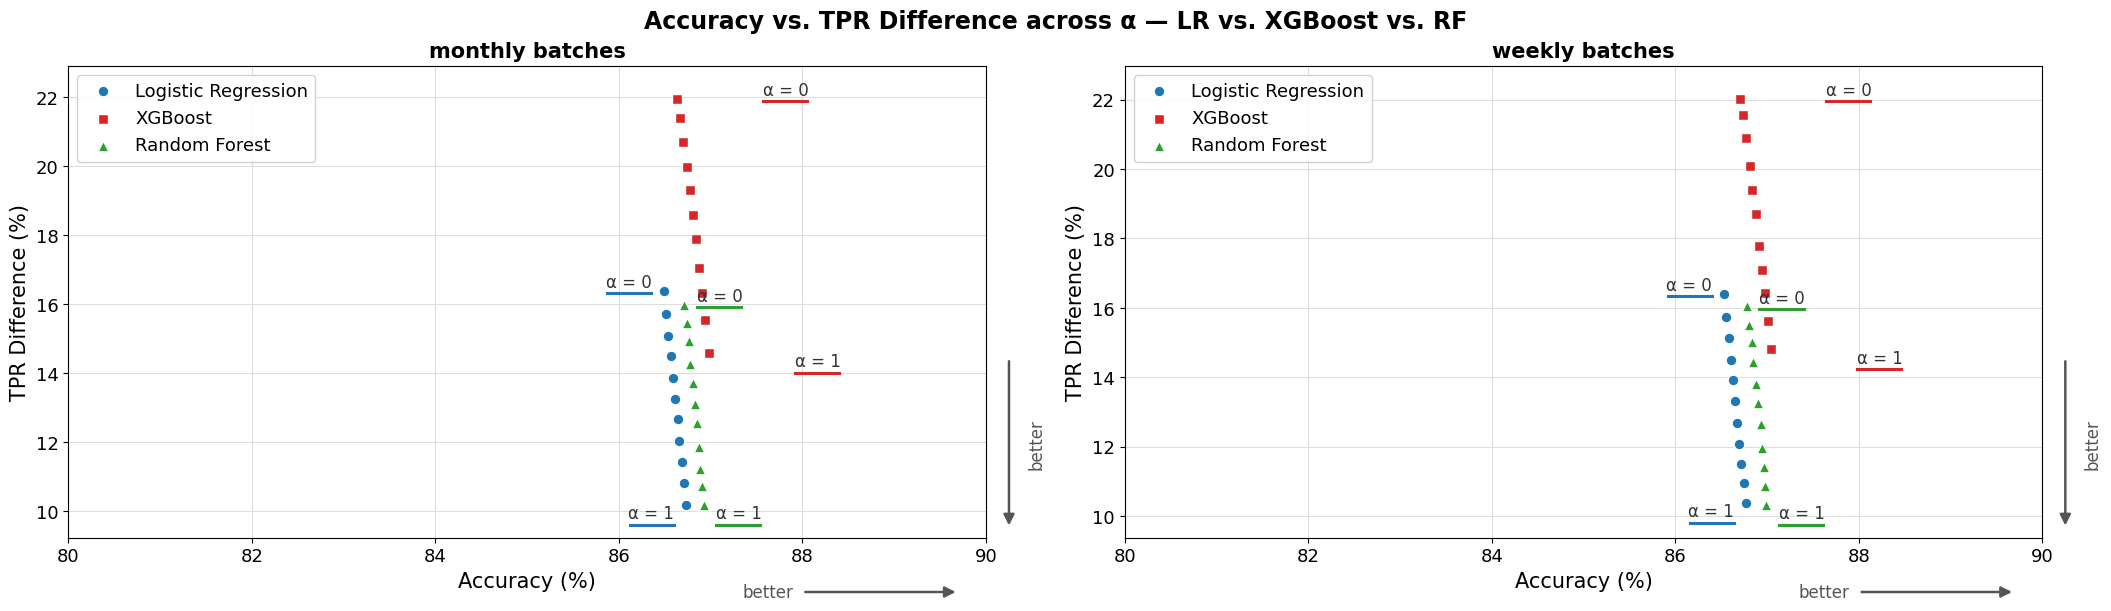

In [19]:
plot_frontier('monthly', 'tpr_diff')
plot_frontier('weekly', 'tpr_diff')
plot_frontier_pair('tpr_diff')

### FPR Difference

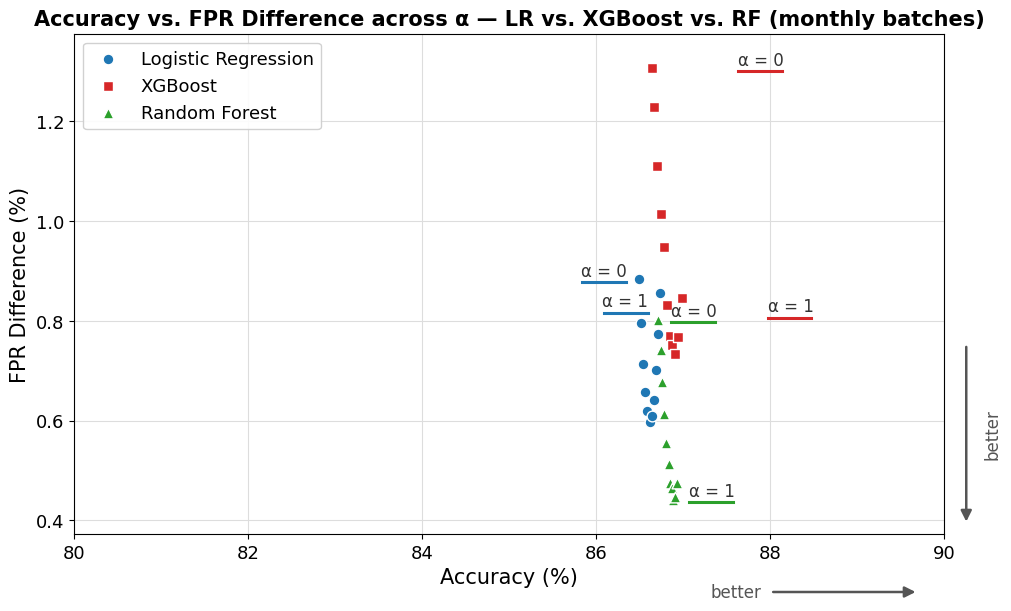

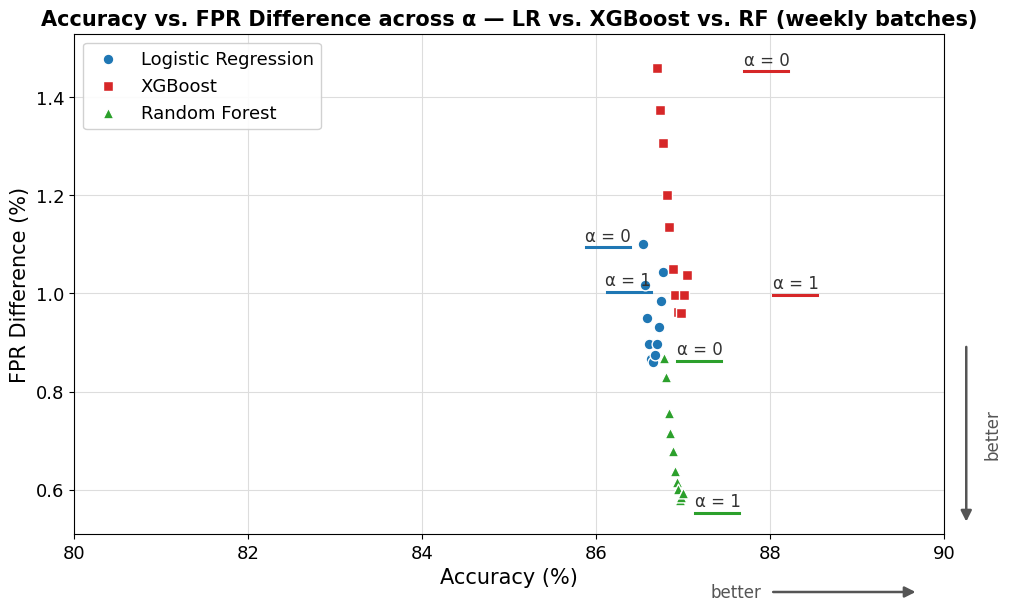

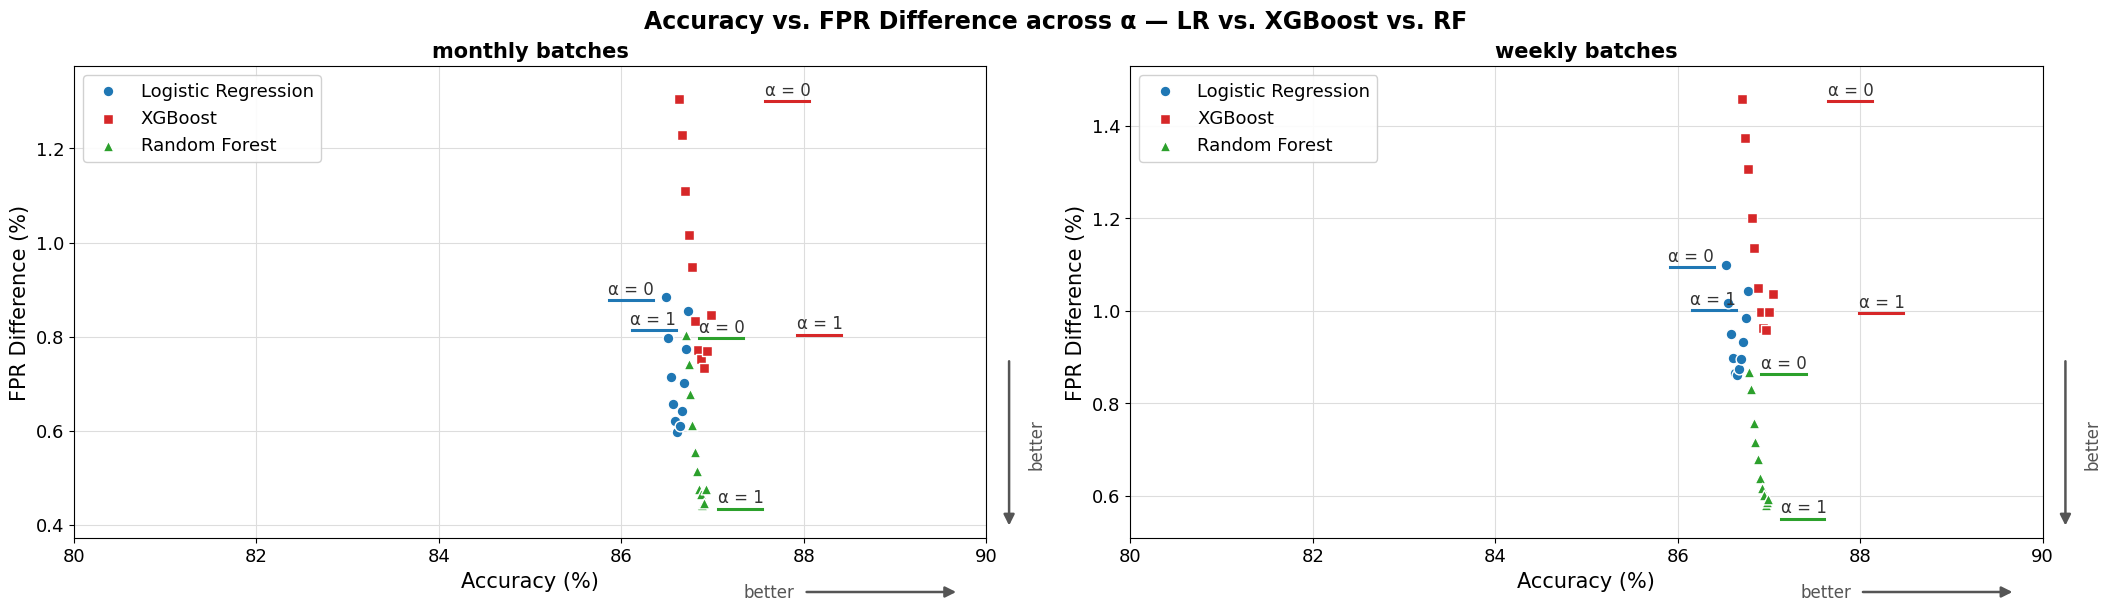

In [20]:
plot_frontier('monthly', 'fpr_diff')
plot_frontier('weekly', 'fpr_diff')
plot_frontier_pair('fpr_diff')

### AUC-ROC

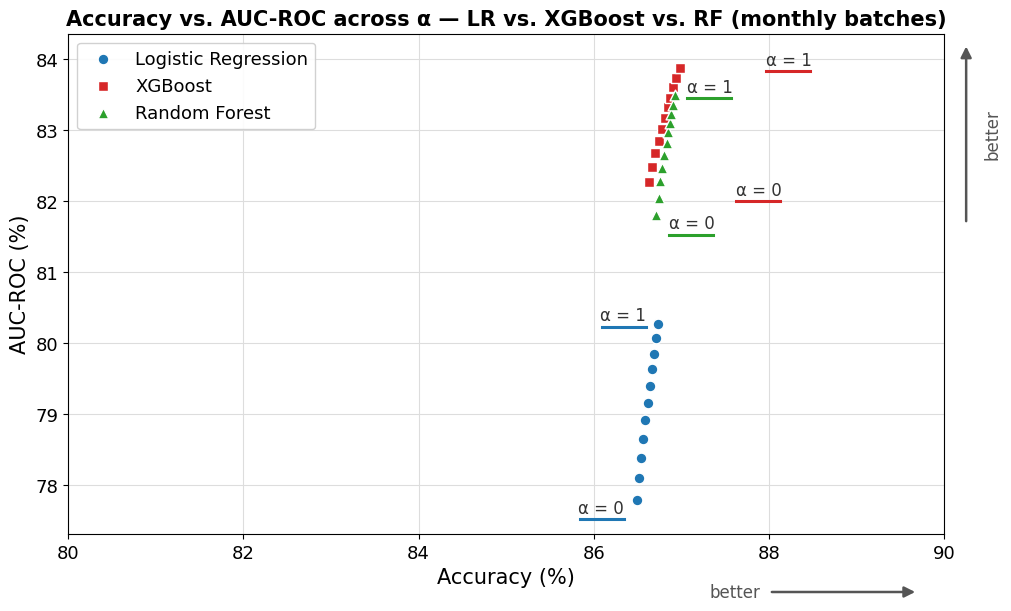

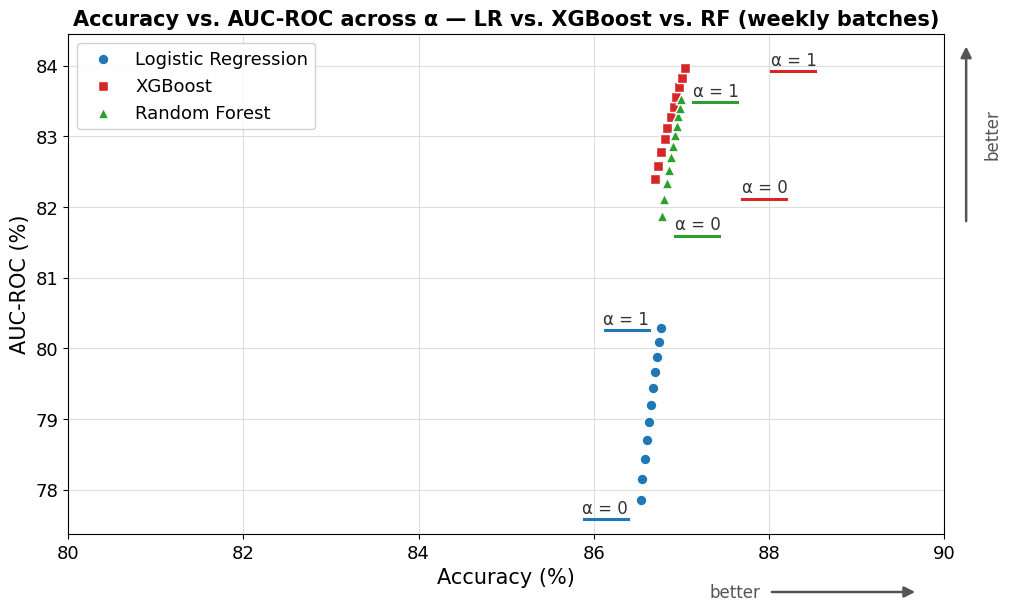

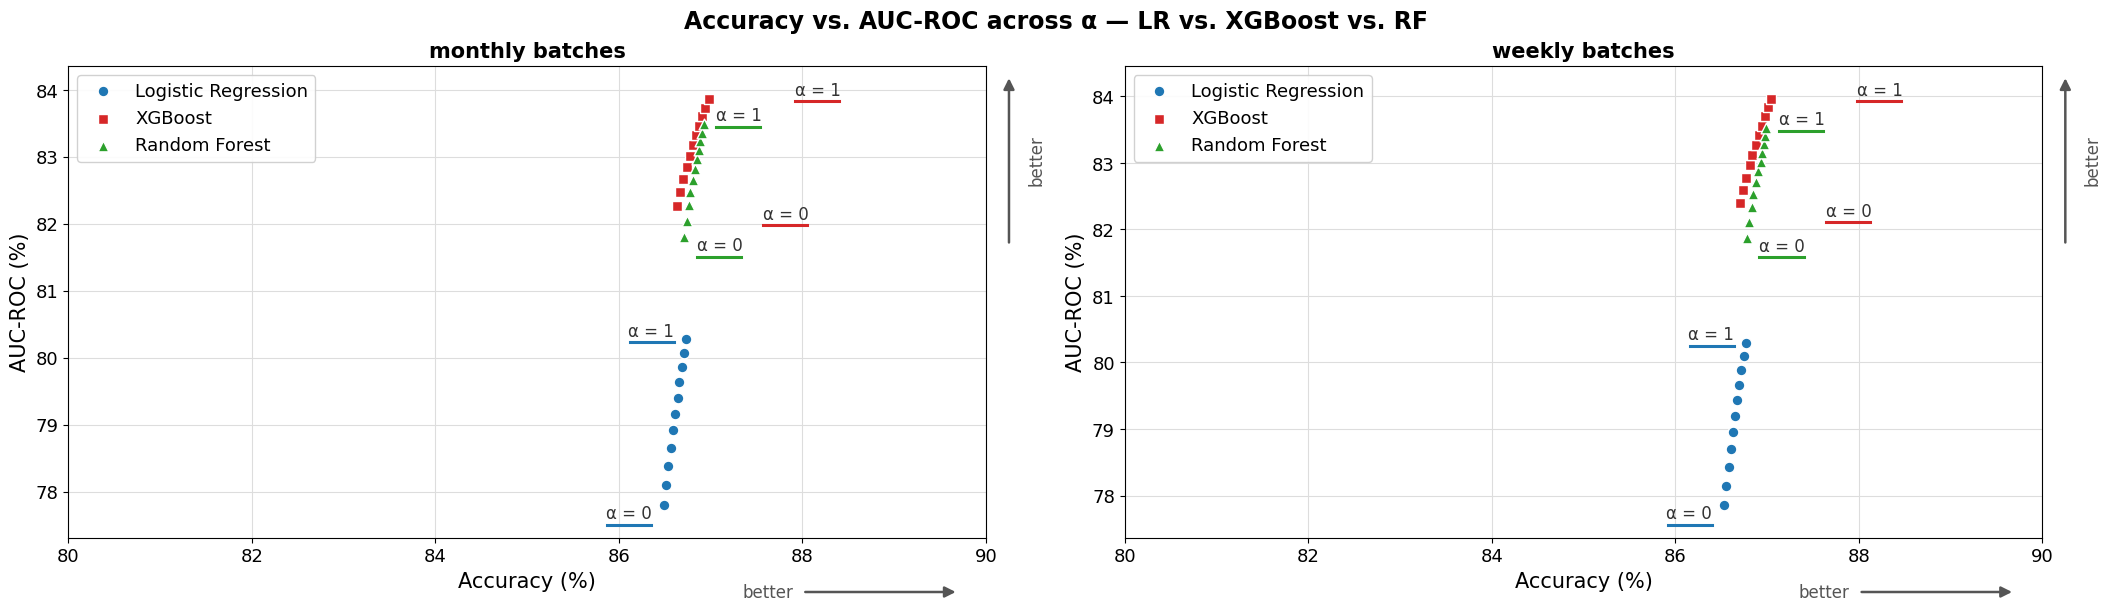

In [21]:
plot_frontier('monthly', 'auc')
plot_frontier('weekly', 'auc')
plot_frontier_pair('auc')

## Accuracy × temporal metrics frontier — LR vs. XGBoost vs. Random Forest (varying alpha)

Same filters and visuals as the frontiers above, with the y axis taken from `temporal_results_df.csv`. All three metrics are computed on the DP Diff. series of each run (`compute_temporal_metrics`), and for all of them lower is better:
- **Maximum Bias**: largest |DP| over the batches;
- **Temporal Stability**: mean change in DP between consecutive batches;
- **Maximum Bias Difference**: largest jump in DP between consecutive batches.

Each point is one `alpha` of `abcinml`: mean accuracy over the batches and mean temporal metric over the runs of that alpha (one per forecast window).

**Random Forest (partial results):** for now it only has `forecast_window = 3`, while LR and XGBoost average 3, 5 and 10. Restricting LR/XGBoost to `fw = 3` moves their points by at most ~0.15 pp, so the comparison holds, but the RF points will still change once windows 5 and 10 are run.

In [22]:
temporal_df = load_filtered('temporal_results_df.csv', FRONTIER_MODELS)
TEMPORAL_METRICS = ['Maximum Bias', 'Temporal Stability', 'Maximum Bias Difference']


def temporal_frontier_points(model_name, batch_type, metric):
    """Mean accuracy (assessment) and mean temporal metric (temporal_results), in %, per alpha."""
    acc = frontier_points(model_name, batch_type, 'auc')['acc']
    tmp = temporal_df[
        (temporal_df['model_name'] == model_name)
        & (temporal_df['batch_type'] == batch_type)
        & (temporal_df['baseline'] == 'abcinml')
    ]
    return pd.concat([acc, tmp.groupby('alpha')[metric].mean().sort_index() * 100], axis=1)


pd.concat({m: temporal_frontier_points(m, 'monthly', 'Maximum Bias') for m in FRONTIER_MODELS}, axis=1).round(2)

logistic_regression              xgboost              random_forest  \
                      acc Maximum Bias     acc Maximum Bias           acc   
alpha                                                                       
0.0                 86.49         8.70   86.63         8.38         86.71   
0.1                 86.51         8.66   86.67         8.98         86.74   
0.2                 86.54         8.60   86.70         8.29         86.76   
0.3                 86.56         8.55   86.74         8.14         86.78   
0.4                 86.59         8.51   86.77         8.09         86.80   
0.5                 86.61         8.47   86.81         8.23         86.83   
0.6                 86.64         8.43   86.84         8.13         86.85   
0.7                 86.66         8.35   86.87         8.43         86.87   
0.8                 86.68         8.32   86.90         8.57         86.88   
0.9                 86.70         8.27   86.93         8.71         86.90   
1.0                 86.73         8.25   86.98         8.28         86.92   

                    
      Maximum Bias  
alpha               
0.0           6.95  
0.1           6.78  
0.2           6.59  
0.3           6.80  
0.4           6.60  
0.5           6.92  
0.6           6.69  
0.7           7.07  
0.8           6.77  
0.9           7.08  
1.0           6.88

### Maximum Bias

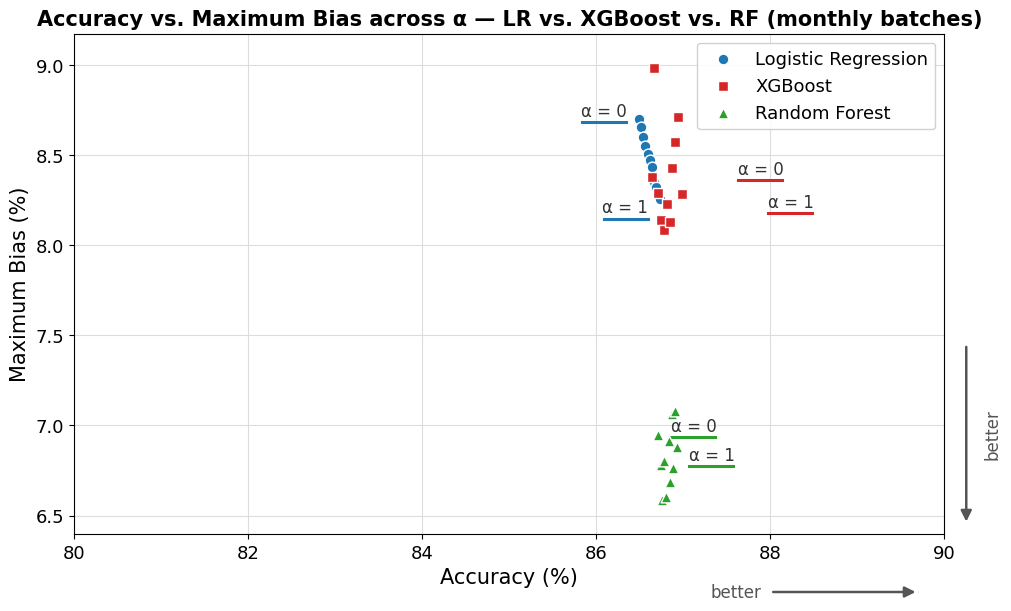

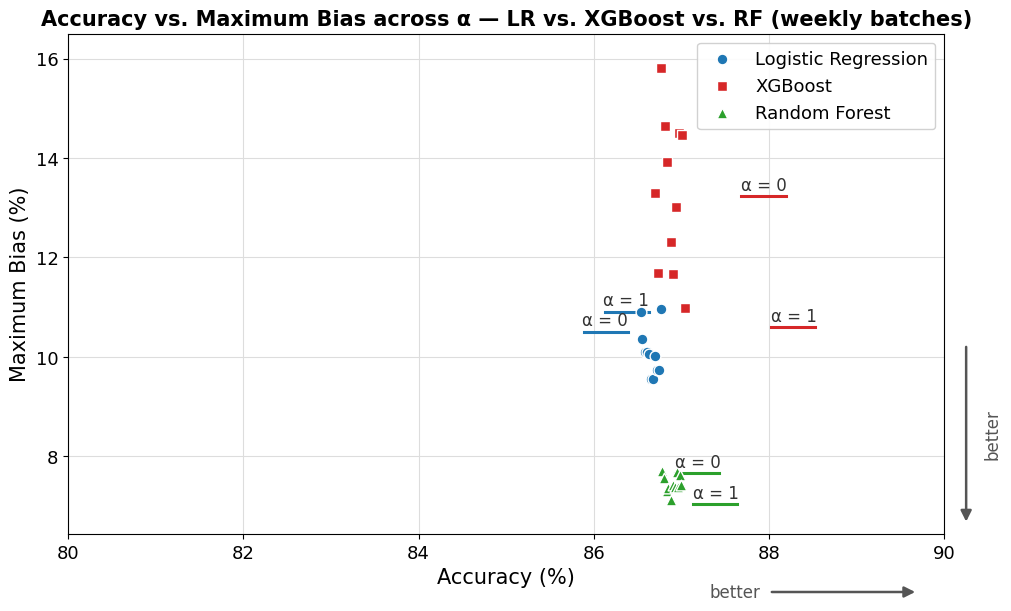

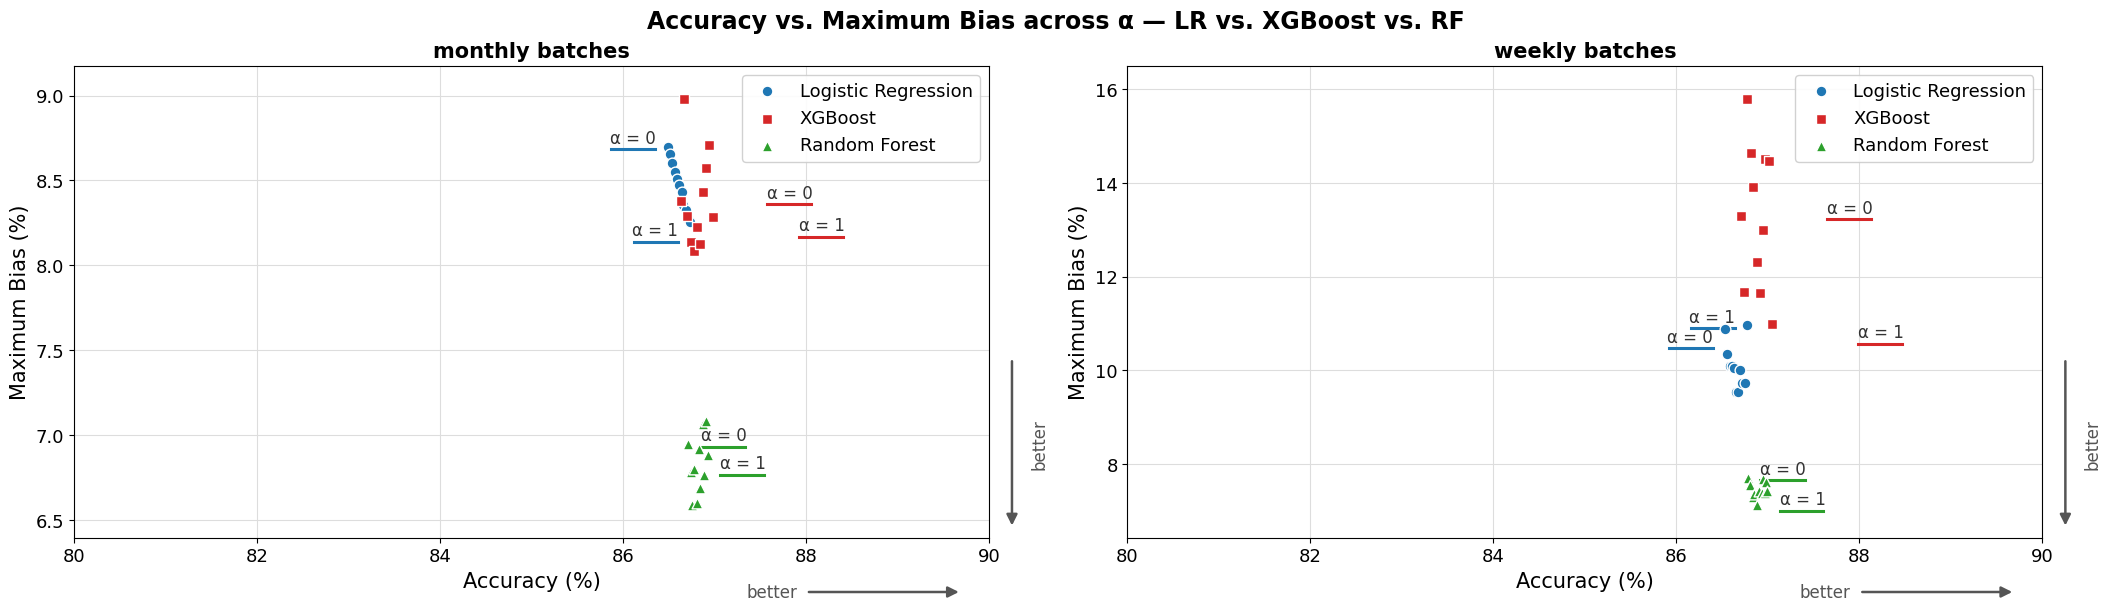

In [23]:
plot_frontier('monthly', 'Maximum Bias', temporal_frontier_points)
plot_frontier('weekly', 'Maximum Bias', temporal_frontier_points)
plot_frontier_pair('Maximum Bias', temporal_frontier_points)

### Temporal Stability

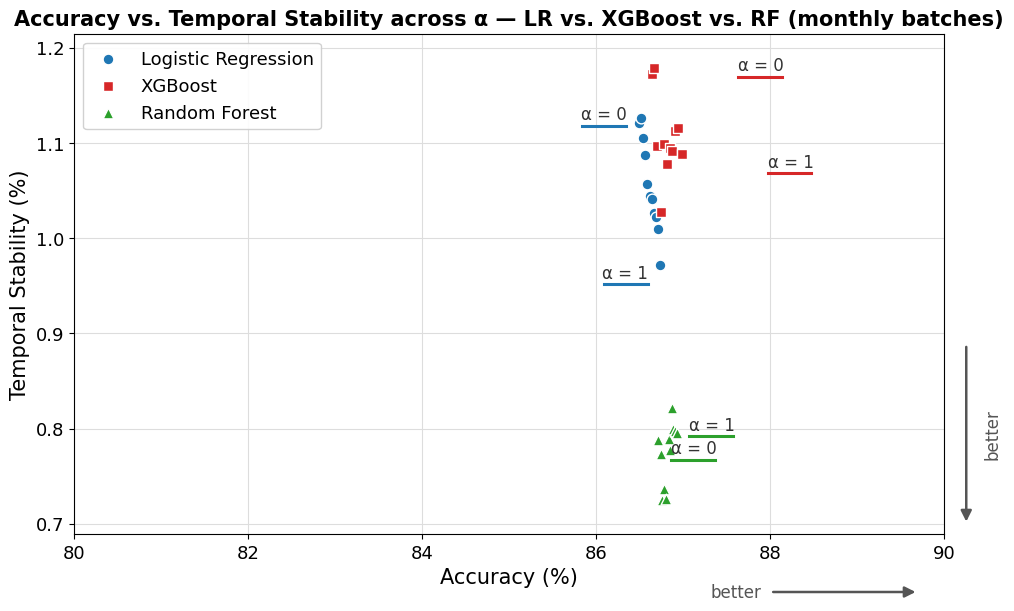

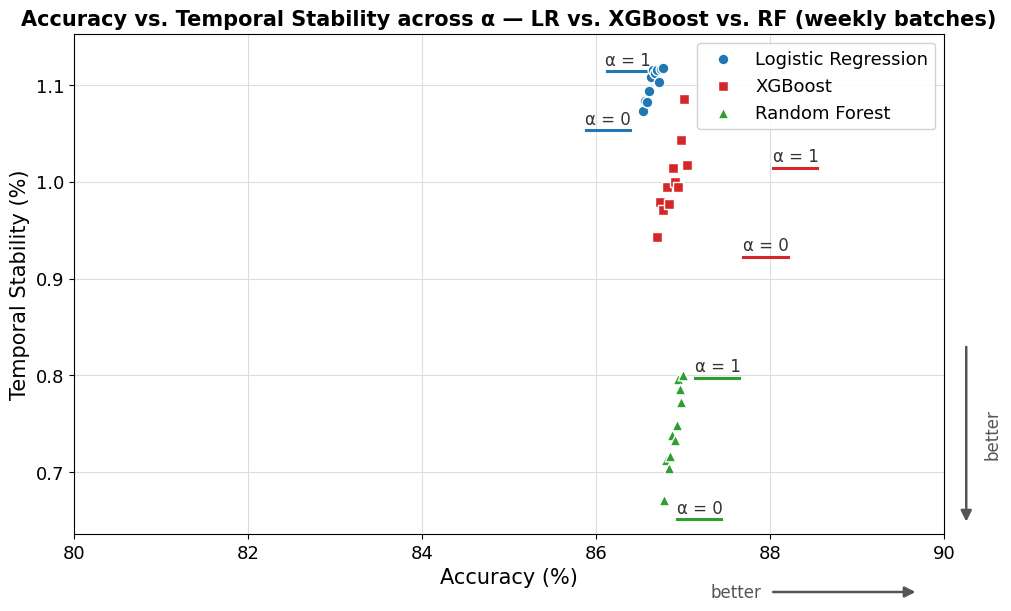

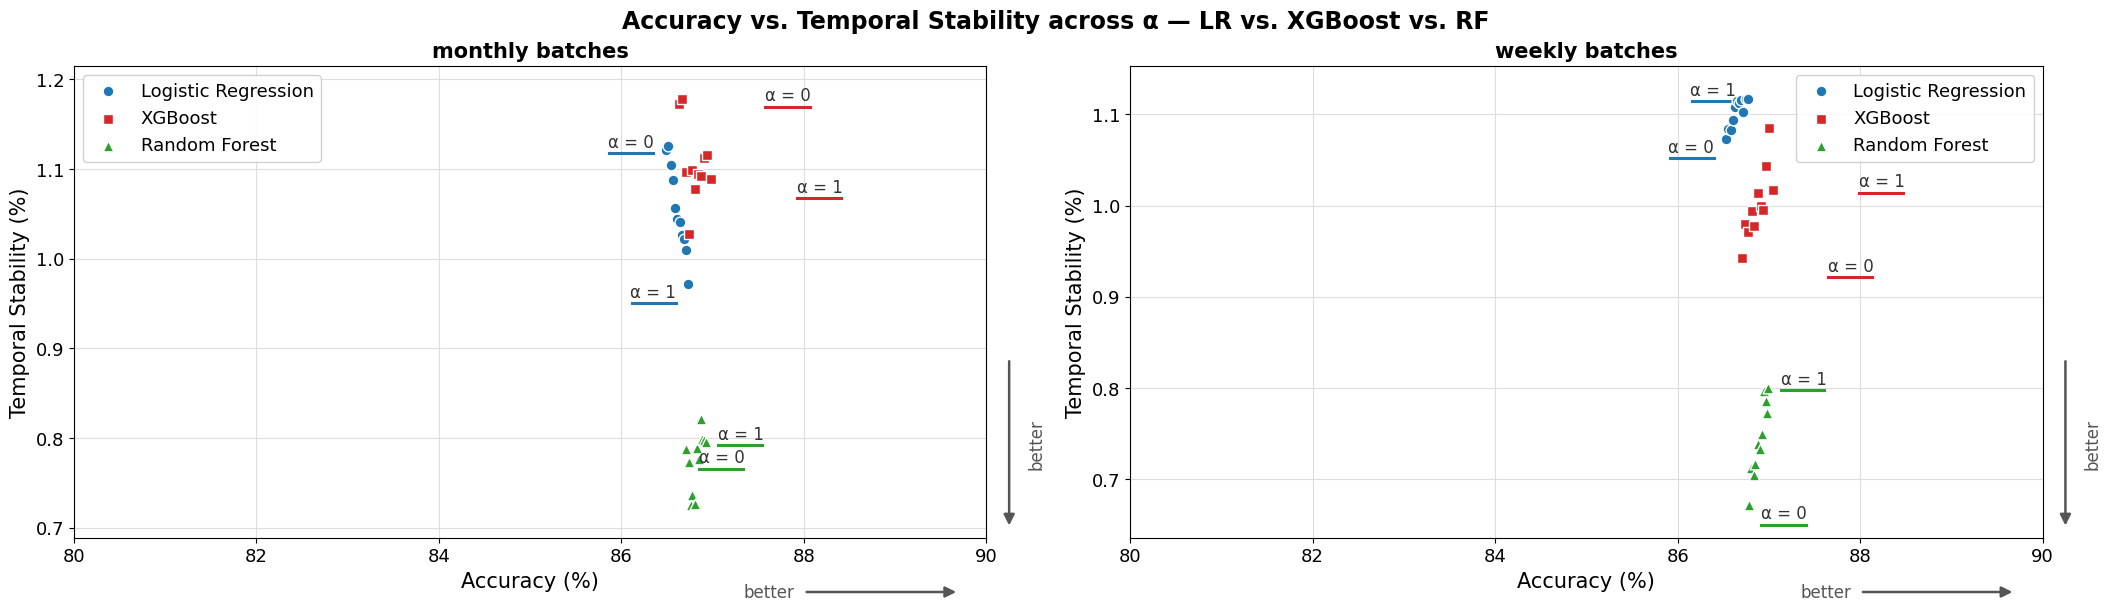

In [24]:
plot_frontier('monthly', 'Temporal Stability', temporal_frontier_points)
plot_frontier('weekly', 'Temporal Stability', temporal_frontier_points)
plot_frontier_pair('Temporal Stability', temporal_frontier_points)

### Maximum Bias Difference

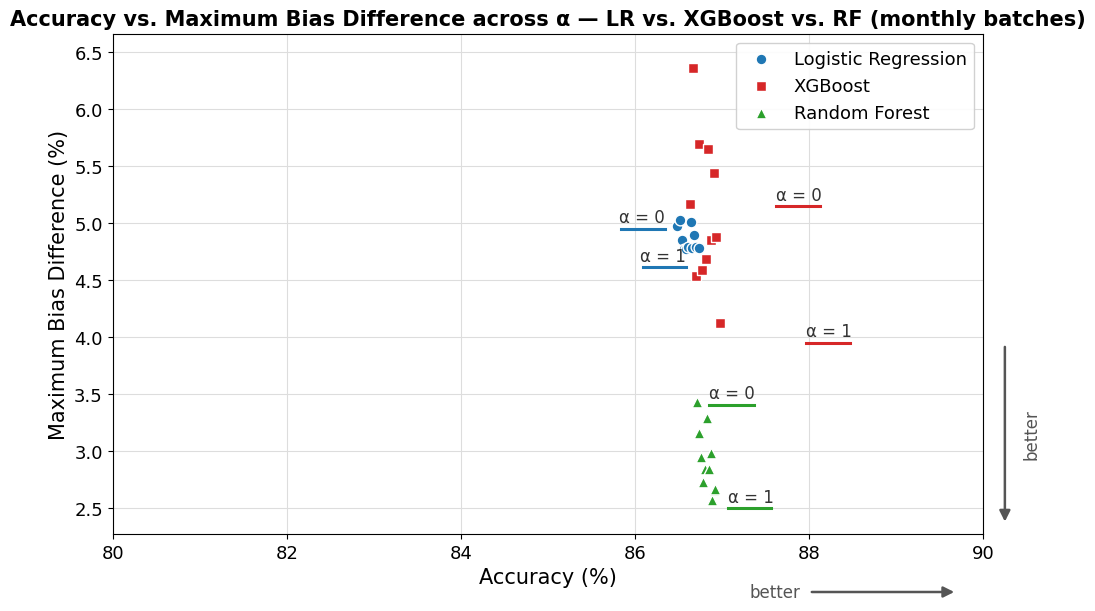

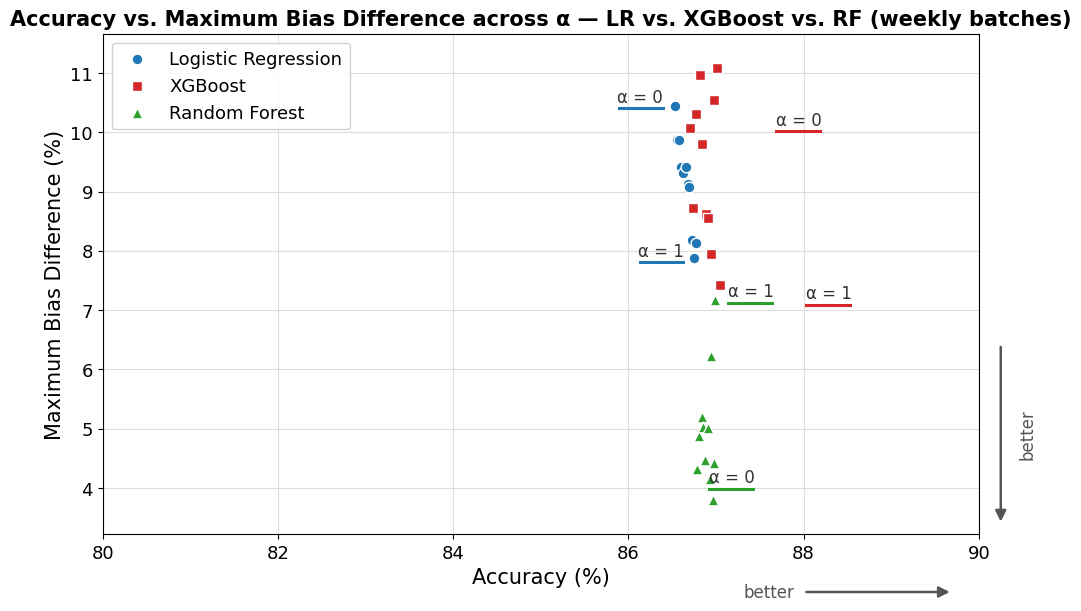

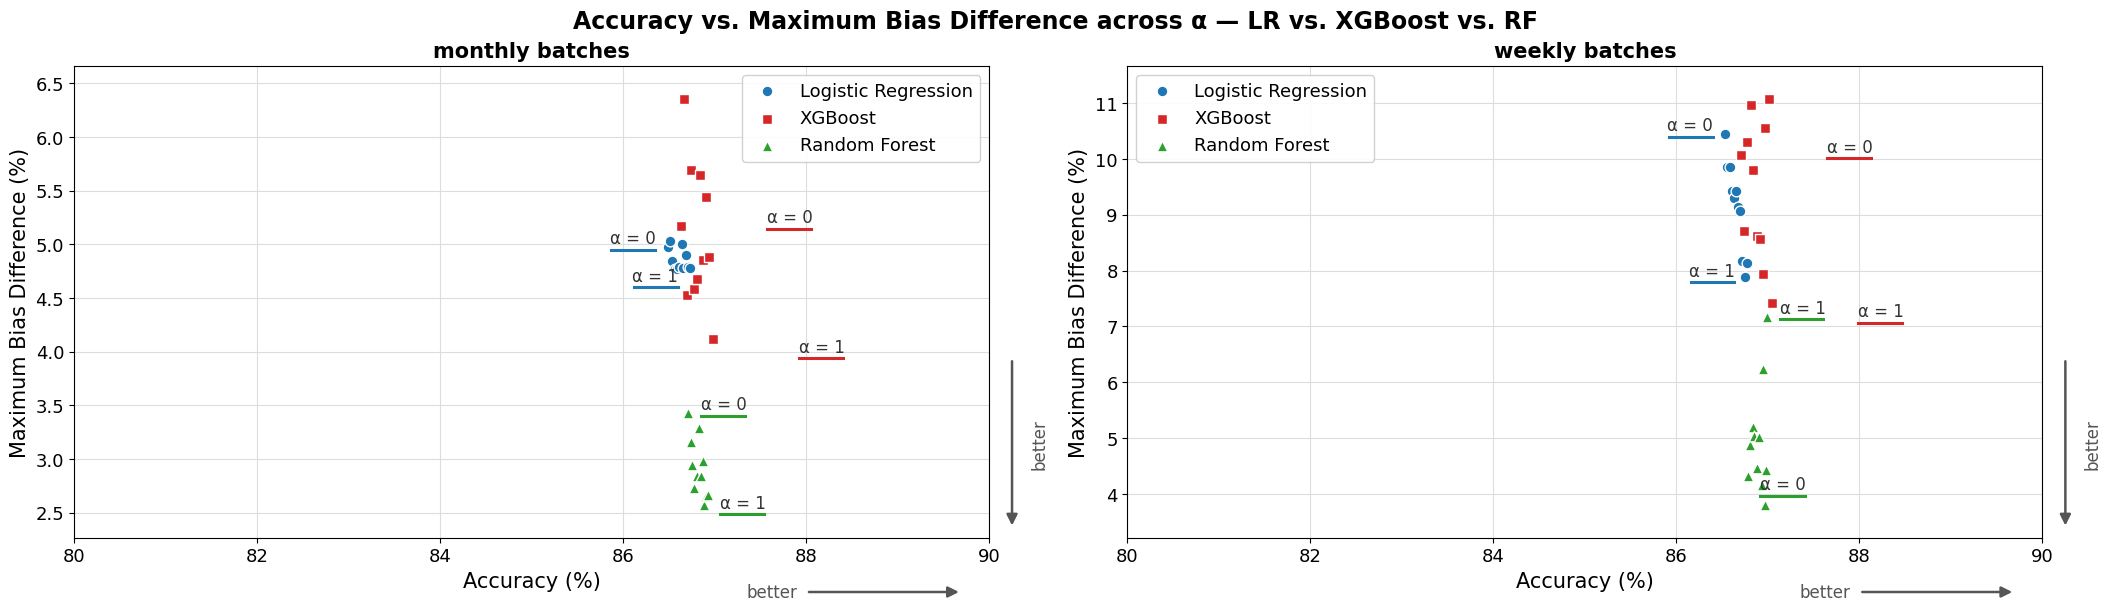

In [25]:
plot_frontier('monthly', 'Maximum Bias Difference', temporal_frontier_points)
plot_frontier('weekly', 'Maximum Bias Difference', temporal_frontier_points)
plot_frontier_pair('Maximum Bias Difference', temporal_frontier_points)